# Sumativa 1: Análisis Estadístico

## Incumplimiento de plazos en envíos de productos electrónicos

**Asignatura:** Estadística Computacional para la Toma de Decisiones
**Dataset:** E-Commerce Shipping Data  
**Integrantes:** Marco Álvarez Araya / Ricardo Jaramillo 
**Fecha:** 14-10-2026  
**Docente:** Dr. Jean Paul Maidana González  
**Evaluaciones que cubre:** Formativa 1 y Sumativa 1 (Fase 2)  

## Objetivo
Caracterizar los envíos y analizar las relaciones entre sus características y el cumplimiento del plazo de entrega, mediante estadística descriptiva, estimación por intervalos de confianza y pruebas de hipótesis.

## Problema de decisión
Una empresa de comercio electrónico debe decidir dónde concentrar recursos logísticos (monitoreo, priorización de despachos, elección del medio de transporte) para reducir los envíos fuera de plazo. La decisión se toma con información incompleta: solo se observa una muestra de envíos y se desconoce cómo se construyó el archivo. Este notebook cuantifica esa incertidumbre y examina qué asociaciones se mantienen en una comparación exploratoria y cuáles dependen de la estructura del conjunto de datos.

## Organización del notebook
| Sección | Contenido | Evaluación |
|---|---|---|
| 0 | Configuración, semilla y entorno | Reproducibilidad |
| 1 | Carga, calidad y decisiones de tratamiento | S1 · Preparación y carga |
| 2 | Análisis exploratorio univariado y bivariado; estructura del archivo | F1 y S1 · ID1.2 |
| 3 | Estimación puntual e intervalos de confianza al 95 % | F1 y S1 · ID1.3 |
| 4 | Pruebas de hipótesis y análisis de sensibilidad | F1 y S1 · ID1.4 |
| 5 | Síntesis e insumos para S2 y S3 | S1 · Informe de avance |

Cada tabla y figura se exporta a `resultados/tablas/` y `resultados/figuras/` con identificadores estables. El informe debe citar las salidas de esta versión ejecutada.


## 0. Configuración del entorno

Se centralizan las librerías, la semilla, los niveles de confianza y significancia, la paleta de colores y las funciones que exportan figuras y tablas. Fijar estos elementos en una sola celda garantiza que todas las secciones usen los mismos criterios y que el notebook pueda ejecutarse de principio a fin con resultados idénticos.

El nivel de significancia α = 0,05 y la confianza del 95 % son convenciones del análisis aplicado; su justificación en el contexto del problema se desarrolla en la sección 4. La tabla final registra las versiones con las que se generaron los resultados.

In [1]:
# Librerías utilizadas en todo el notebook.
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

# Semilla fija. S1 no usa procedimientos aleatorios, pero S2 (bootstrap,
# permutación y Monte Carlo) partirá de este mismo notebook.
SEED = 42
rng = np.random.default_rng(SEED)

# Niveles de confianza y significancia usados en todo el análisis.
CONFIANZA = 0.95
ALFA = 0.05
Z_CRITICO = stats.norm.ppf(1 - ALFA / 2)

# Paleta: un color por estado de entrega (par validado para daltonismo,
# separación ΔE ≥ 16 en protanopía) y un gris para referencias.
COLOR_A_TIEMPO = "#2A74B0"
COLOR_FUERA_PLAZO = "#BC5A45"
COLOR_SERIE = "#2A74B0"
COLOR_REFERENCIA = "#7F7F7F"
COLORES_ESTADO = {0: COLOR_A_TIEMPO, 1: COLOR_FUERA_PLAZO}
ETIQUETAS_ESTADO = {0: "A tiempo", 1: "Fuera de plazo"}

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 9.5,
    "axes.titlesize": 10,
    "axes.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#9A9A9A",
    "axes.grid": True,
    "grid.color": "#E3E3E3",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "legend.frameon": False,
})

# Carpetas de salida: cada figura y tabla citada en los informes
# se guarda aquí con el mismo identificador.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_FIGURAS = RAIZ / "resultados" / "figuras"
DIR_TABLAS = RAIZ / "resultados" / "tablas"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_TABLAS.mkdir(parents=True, exist_ok=True)


def formato_es(valor, decimales=1):
    """Formatea un número con convención chilena: 3.634,0."""
    texto = f"{valor:,.{decimales}f}"
    return texto.replace(",", "§").replace(".", ",").replace("§", ".")


def guardar_figura(fig, nombre):
    """Guarda la figura en resultados/figuras/<nombre>.png.

    El título "Figura N" se muestra en el notebook, pero se omite en el archivo:
    los informes agregan su propio pie de figura con la referencia al notebook.
    """
    titulos = [fig._suptitle] if fig._suptitle is not None else []
    titulos += [ax.title for ax in fig.axes if ax.get_title().startswith("Figura")]
    for titulo in titulos:
        titulo.set_visible(False)
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    for titulo in titulos:
        titulo.set_visible(True)


def guardar_tabla(tabla, nombre, index=True):
    """Guarda la tabla en resultados/tablas/<nombre>.csv."""
    tabla.to_csv(DIR_TABLAS / f"{nombre}.csv", index=index, encoding="utf-8")


# Registro del entorno de ejecución.
entorno = pd.Series({
    "Python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
}, name="version")
display(entorno.to_frame())

,version
Python,3.13.16
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
matplotlib,3.11.2


## 1. Carga y revisión de database

Se carga el dataset denominado " E-Commerce Shipping desde la carpeta de los datos originales, sin modificar el archivo original.

Las variables objetivos se interpretan como:

- 1: Entrega fuera de Plazo
- 0: Entrega a tiempo

In [2]:
# Carpeta raiz del proyecto.
from pathlib import Path
import pandas as pd
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Ruta del Archivo csv. En el repositorio integrado (S1/, S2/), el CSV está en
# la carpeta datos/ de la raíz común; si no, en la raíz de S1 (estructura original).
raiz_datos = raiz.parent if (raiz.parent / "datos" / "originales").is_dir() else raiz
ruta_csv = raiz_datos / "datos" / "originales" / "ecommerce-shipping.csv"

# Comprobación de existencia.
if not ruta_csv.is_file():
    raise FileNotFoundError(f"No se encontró el dataset en: {ruta_csv}")

# Cargar los datos sin modificar el CSV original.
df_original = pd.read_csv(ruta_csv)

print("Número de registros:", df_original.shape[0])
print("Número de variables:", df_original.shape[1])

# Mostrar las primeras cinco filas.
df_original.head()

Número de registros: 10999
Número de variables: 12


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


### 1.1. Estructura y calidad inicial de los datos

Se revisan los tipos de datos, la cantidad de valores faltantes,
los valores distintos por variable y la presencia de registros
duplicados o identificadores repetidos.

Estos controles se realizan sin modificar los datos originales.

In [3]:
# Resumen de calidad por variable.
resumen_calidad = pd.DataFrame({
    "tipo_en_python": df_original.dtypes.astype(str),
    "valores_distintos": df_original.nunique(),
    "faltantes": df_original.isna().sum(),
    "faltantes_porcentaje": (
        df_original.isna().mean() * 100
    ).round(2)
})

# Revisar duplicados.
print("Filas duplicadas:", df_original.duplicated().sum())
print("Identificadores repetidos:", df_original["ID"].duplicated().sum())

# Mostrar el resumen.
resumen_calidad

Filas duplicadas: 0
Identificadores repetidos: 0


,tipo_en_python,valores_distintos,faltantes,faltantes_porcentaje
ID,int64,10999,0,0.0
Warehouse_block,str,5,0,0.0
Mode_of_Shipment,str,3,0,0.0
Customer_care_calls,int64,6,0,0.0
Customer_rating,int64,5,0,0.0
Cost_of_the_Product,int64,215,0,0.0
Prior_purchases,int64,8,0,0.0
Product_importance,str,3,0,0.0
Gender,str,2,0,0.0
Discount_offered,int64,65,0,0.0


### 1.2. Revisión de rangos y categorías

Se examinan los valores mínimos y máximos de las variables
numéricas y las categorías presentes en las variables cualitativas.

También se comprueba que la calificación del cliente esté entre
1 y 5, que la variable objetivo contenga únicamente 0 y 1, y que
el costo y el peso sean positivos.

El identificador ID no se considera una variable explicativa.
Estas comprobaciones no modifican ni eliminan registros.

In [4]:
from IPython.display import display

# Revisar los rangos de las variables almacenadas como números.
variables_numericas = [
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms"
]

rangos = pd.DataFrame({
    "minimo": df_original[variables_numericas].min(),
    "maximo": df_original[variables_numericas].max()
})

print("RANGOS OBSERVADOS")
display(rangos)

# Revisar las categorías sin cambiar su codificación.
variables_categoricas = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender",
    "Reached.on.Time_Y.N"
]

print("\nCATEGORÍAS OBSERVADAS")
for variable in variables_categoricas:
    print(f"{variable}: {df_original[variable].unique().tolist()}")

# Contar registros que incumplen reglas básicas.
controles = pd.Series({
    "Calificación fuera de 1 a 5": (
        ~df_original["Customer_rating"].between(1, 5)
    ).sum(),
    "Objetivo distinto de 0 o 1": (
        ~df_original["Reached.on.Time_Y.N"].isin([0, 1])
    ).sum(),
    "Costo no positivo": (
        df_original["Cost_of_the_Product"] <= 0
    ).sum(),
    "Peso no positivo": (
        df_original["Weight_in_gms"] <= 0
    ).sum(),
    "Descuento negativo": (
        df_original["Discount_offered"] < 0
    ).sum()
}, name="registros_observados")

print("\nCOMPROBACIONES DE VALIDEZ")
display(controles)

RANGOS OBSERVADOS


,minimo,maximo
Customer_care_calls,2,7
Customer_rating,1,5
Cost_of_the_Product,96,310
Prior_purchases,2,10
Discount_offered,1,65
Weight_in_gms,1001,7846



CATEGORÍAS OBSERVADAS
Warehouse_block: ['D', 'F', 'A', 'B', 'C']
Mode_of_Shipment: ['Flight', 'Ship', 'Road']
Product_importance: ['low', 'medium', 'high']
Gender: ['F', 'M']
Reached.on.Time_Y.N: [1, 0]

COMPROBACIONES DE VALIDEZ


Calificación fuera de 1 a 5    0
Objetivo distinto de 0 o 1     0
Costo no positivo              0
Peso no positivo               0
Descuento negativo             0
Name: registros_observados, dtype: int64

### Conclusión del control inicial

El dataset contiene 10.999 registros y 12 variables. No se
identificaron valores faltantes, filas duplicadas ni identificadores
repetidos.

Los controles aplicados no detectaron calificaciones fuera de
escala, valores inválidos en la variable objetivo, costos o pesos
no positivos ni descuentos negativos.

Estos resultados corresponden a comprobaciones básicas de calidad.
No descartan valores atípicos, sesgos ni otras limitaciones del
conjunto de datos.

### 1.3. Diccionario y clasificación de variables

Cada fila del conjunto de datos representa un registro de envío. El diccionario documenta el significado de las variables, su clasificación estadística y su función en el análisis. Esta clasificación considera las propiedades de la información representada, independientemente del formato utilizado para almacenarla en Python. La distinción entre escalas nominales, ordinales y de razón se fundamenta en Stevens (1946, pp. 678–679).

La variable de respuesta es `Reached.on.Time_Y.N`, cuya codificación adoptada en el proyecto corresponde a 1 para entregas fuera de plazo y 0 para entregas a tiempo. El campo `ID` identifica los registros y se excluye de las variables explicativas. La calificación del cliente y la importancia del producto se consideran ordinales, debido al orden de sus categorías. El peso corresponde a una magnitud continua, aunque el archivo lo registre en gramos enteros.

El diccionario incorpora el tipo de almacenamiento, el número de valores distintos y la cantidad de datos ausentes observados durante la ejecución. La unidad de `Discount_offered` permanece pendiente de confirmación, por lo que no se interpreta automáticamente como porcentaje. Asimismo, el uso predictivo de las llamadas a atención al cliente y de la calificación requiere verificar cuándo se registraron respecto del momento de la entrega.

Fuente del conjunto de datos: [E-Commerce Shipping Data, disponible en Kaggle](https://www.kaggle.com/datasets/prachi13/customer-analytics).

Referencia metodológica: Stevens, S. S. (1946). On the theory of scales of measurement. *Science, 103*(2684), 677–680. https://doi.org/10.1126/science.103.2684.677

In [5]:
import pandas as pd

# Definiciones correspondientes al conjunto E-Commerce Shipping Data.
DICCIONARIO = [
    ("ID", "Identificador del registro",
     "Identificador nominal", "Nominal", "identificador"),

    ("Warehouse_block", "Bloque de almacén",
     "Cualitativa nominal", "Nominal", "explicativa"),

    ("Mode_of_Shipment", "Medio de transporte",
     "Cualitativa nominal", "Nominal", "explicativa"),

    ("Customer_care_calls", "Número de llamadas a atención al cliente",
     "Cuantitativa discreta", "Razón", "explicativa"),

    ("Customer_rating", "Calificación del cliente: de 1 a 5",
     "Cualitativa ordinal", "Ordinal", "explicativa"),

    ("Cost_of_the_Product", "Costo del producto",
     "Cuantitativa monetaria", "Razón", "explicativa"),

    ("Prior_purchases", "Número de compras previas",
     "Cuantitativa discreta", "Razón", "explicativa"),

    ("Product_importance", "Importancia del producto: baja, media o alta",
     "Cualitativa ordinal", "Ordinal", "explicativa"),

    ("Gender", "Género registrado",
     "Cualitativa nominal", "Nominal", "explicativa"),

    ("Discount_offered", "Descuento ofrecido; unidad pendiente de confirmar",
     "Cuantitativa", "Pendiente de confirmar", "explicativa"),

    ("Weight_in_gms", "Peso del producto en gramos",
     "Cuantitativa continua, registrada en gramos enteros",
     "Razón", "explicativa"),

    ("Reached.on.Time_Y.N", "1 = fuera de plazo; 0 = a tiempo",
     "Cualitativa nominal binaria", "Nominal", "objetivo"),
]


def construir_diccionario(datos, definiciones):
    """Documenta las variables y calcula su perfil sin modificar los datos."""
    if not isinstance(datos, pd.DataFrame) or datos.empty:
        raise ValueError("Se requiere un DataFrame con registros.")

    tabla = pd.DataFrame(
        definiciones,
        columns=["variable", "descripcion", "naturaleza", "escala", "uso"],
    )

    if tabla["variable"].duplicated().any() or not datos.columns.is_unique:
        raise ValueError("Existen nombres de variables duplicados.")

    declaradas = set(tabla["variable"])
    observadas = set(datos.columns)

    if declaradas != observadas:
        raise ValueError(
            f"Columnas sin documentar: {sorted(observadas - declaradas)}. "
            f"Variables ausentes en los datos: {sorted(declaradas - observadas)}."
        )

    perfiles = []

    for variable in tabla["variable"]:
        serie = datos[variable]
        vacios = serie.astype("string").str.strip().eq("").fillna(False)
        ausentes = serie.isna() | vacios

        perfiles.append({
            "variable": variable,
            "tipo_en_python": str(serie.dtype),
            "valores_distintos": int(serie.mask(ausentes).nunique()),
            "faltantes": int(ausentes.sum()),
            "faltantes_porcentaje": round(
                float(ausentes.mean() * 100), 2
            ),
        })

    return tabla.merge(
        pd.DataFrame(perfiles),
        on="variable",
        validate="one_to_one",
    )


if "df_original" not in globals():
    raise NameError(
        "Primero debe ejecutarse la celda que carga df_original."
    )

diccionario = construir_diccionario(df_original, DICCIONARIO)

OBJETIVO = diccionario.loc[
    diccionario["uso"].eq("objetivo"), "variable"
].item()

EXPLICATIVAS = diccionario.loc[
    diccionario["uso"].eq("explicativa"), "variable"
].tolist()

print(f"Variables documentadas: {len(diccionario)}")
print(f"Variable objetivo: {OBJETIVO}")

guardar_tabla(diccionario, "diccionario_variables", index=False)
print("Diccionario de variables (sección 1.3)")
display(diccionario)

Variables documentadas: 12
Variable objetivo: Reached.on.Time_Y.N
Diccionario de variables (sección 1.3)


,variable,descripcion,naturaleza,escala,uso,tipo_en_python,valores_distintos,faltantes,faltantes_porcentaje
0,ID,Identificador del registro,Identificador nominal,Nominal,identificador,int64,10999,0,0.0
1,Warehouse_block,Bloque de almacén,Cualitativa nominal,Nominal,explicativa,str,5,0,0.0
2,Mode_of_Shipment,Medio de transporte,Cualitativa nominal,Nominal,explicativa,str,3,0,0.0
3,Customer_care_calls,Número de llamadas a atención al cliente,Cuantitativa discreta,Razón,explicativa,int64,6,0,0.0
4,Customer_rating,Calificación del cliente: de 1 a 5,Cualitativa ordinal,Ordinal,explicativa,int64,5,0,0.0
5,Cost_of_the_Product,Costo del producto,Cuantitativa monetaria,Razón,explicativa,int64,215,0,0.0
6,Prior_purchases,Número de compras previas,Cuantitativa discreta,Razón,explicativa,int64,8,0,0.0
7,Product_importance,"Importancia del producto: baja, media o alta",Cualitativa ordinal,Ordinal,explicativa,str,3,0,0.0
8,Gender,Género registrado,Cualitativa nominal,Nominal,explicativa,str,2,0,0.0
9,Discount_offered,Descuento ofrecido; unidad pendiente de confirmar,Cuantitativa,Pendiente de confirmar,explicativa,int64,65,0,0.0


### 1.4. Estructura del identificador y decisiones de tratamiento

Se verifica si `ID` corresponde a un correlativo alineado con el orden de las filas. Esta comprobación es necesaria porque, si el archivo fue ensamblado por bloques, el orden de los registros puede contener información sobre su origen; la sección 2.6 retoma este punto.

La tabla de decisiones documenta qué se hizo con cada situación detectada y por qué. Ningún registro se elimina: el análisis principal se realiza sobre los 10.999 envíos.

In [6]:
# El ID coincide con el orden de las filas (1, 2, ..., n)?
id_secuencial = df_original["ID"].equals(
    pd.Series(range(1, len(df_original) + 1), index=df_original.index)
)
print("ID secuencial y alineado con el orden del archivo:", id_secuencial)

# Decisiones de tratamiento de la información (Tabla 1).
decisiones = pd.DataFrame([
    ("Valores faltantes (0 en las 12 variables)",
     "No se imputa. Se documenta como insumo de S3, donde la imputación "
     "requerirá inducir faltantes de forma controlada."),
    ("Filas duplicadas e ID repetidos (0)",
     "No se elimina ningún registro."),
    ("Valores altos de Discount_offered (cola derecha hasta 65)",
     "Se conservan: no hay evidencia suficiente para clasificarlos como errores de captura. Se reporta la mediana junto a la media."),
    ("Unidad de Discount_offered no documentada",
     "Se analiza en su escala original, sin interpretarla como porcentaje."),
    ("Momento de registro de descuento, llamadas y calificación desconocido",
     "Se interpretan como asociaciones, no como causas; se declara el riesgo "
     "de que sean posteriores al resultado (fuga de información)."),
    ("Campo ID",
     "Se excluye como variable explicativa, pero se usa como diagnóstico de "
     "la estructura del archivo (sección 2.6)."),
], columns=["situacion", "decision"])

guardar_tabla(decisiones, "tab01_decisiones_tratamiento", index=False)
print("Tabla 1. Decisiones de tratamiento de la información")
with pd.option_context("display.max_colwidth", None):
    display(decisiones)

ID secuencial y alineado con el orden del archivo: True
Tabla 1. Decisiones de tratamiento de la información


,situacion,decision
0,Valores faltantes (0 en las 12 variables),"No se imputa. Se documenta como insumo de S3, donde la imputación requerirá inducir faltantes de forma controlada."
1,Filas duplicadas e ID repetidos (0),No se elimina ningún registro.
2,Valores altos de Discount_offered (cola derecha hasta 65),Se conservan: no hay evidencia suficiente para clasificarlos como errores de captura. Se reporta la mediana junto a la media.
3,Unidad de Discount_offered no documentada,"Se analiza en su escala original, sin interpretarla como porcentaje."
4,"Momento de registro de descuento, llamadas y calificación desconocido","Se interpretan como asociaciones, no como causas; se declara el riesgo de que sean posteriores al resultado (fuga de información)."
5,Campo ID,"Se excluye como variable explicativa, pero se usa como diagnóstico de la estructura del archivo (sección 2.6)."


## 2. Análisis exploratorio de datos

El análisis exploratorio caracteriza las variables del conjunto de datos y examina sus relaciones con el cumplimiento del plazo de entrega. Se utilizan tablas de frecuencias, medidas descriptivas y representaciones gráficas para identificar patrones que orienten la posterior estimación de parámetros y formulación de pruebas de hipótesis.

La relevancia del problema se vincula con el papel de la distribución en la experiencia del cliente. Flórez Oviedo y López Hincapié (2023) destacan la importancia de la entrega de última milla dentro de la cadena de suministro y su relación con la satisfacción del destinatario. Este antecedente permite contextualizar el estudio, aunque el conjunto de datos disponible no permite atribuir los retrasos específicamente a esa etapa logística.

### 2.1. Distribución del cumplimiento del plazo de entrega

La variable `Reached.on.Time_Y.N` distingue entre entregas a tiempo, codificadas como 0, y entregas fuera de plazo, codificadas como 1. Su distribución se describe mediante frecuencias absolutas y porcentajes calculados sobre el total de registros.

Esta caracterización establece la proporción observada de incumplimiento y permite reconocer la representación de ambos grupos antes de compararlos. Los resultados describen el conjunto analizado; su generalización requiere información adicional sobre la población de origen y el procedimiento de selección de los registros.

Tabla 2. Distribución de los envíos según cumplimiento del plazo


,codigo,estado_entrega,frecuencia,porcentaje
0,0,A tiempo,4436,40.33
1,1,Fuera de plazo,6563,59.67


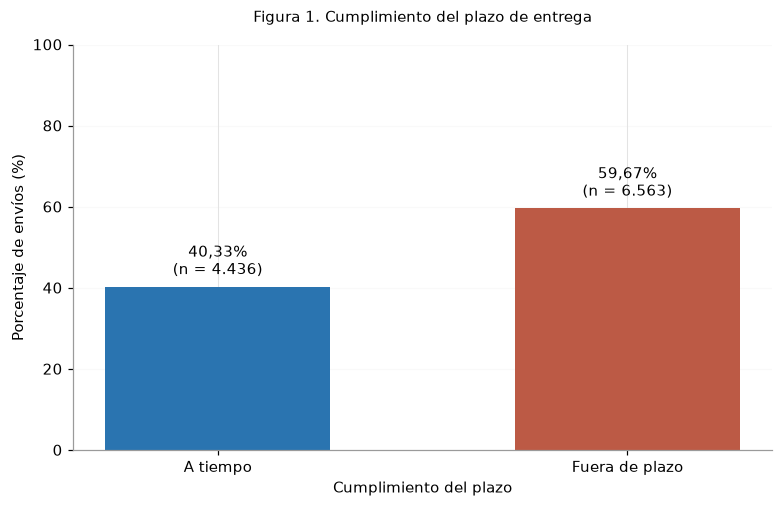

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def resumir_cumplimiento(datos, variable="Reached.on.Time_Y.N"):
    """Calcula frecuencias y porcentajes de cumplimiento del plazo."""
    if variable not in datos.columns:
        raise KeyError(f"No se encontró la variable {variable}.")

    serie = datos[variable]

    if serie.empty or serie.isna().any():
        raise ValueError(
            "La variable objetivo está vacía o contiene faltantes."
        )

    if not serie.isin([0, 1]).all():
        raise ValueError(
            "La variable objetivo debe contener únicamente 0 y 1."
        )

    frecuencias = serie.value_counts().reindex([0, 1], fill_value=0)

    return pd.DataFrame({
        "codigo": [0, 1],
        "estado_entrega": ["A tiempo", "Fuera de plazo"],
        "frecuencia": frecuencias.to_numpy(),
        "porcentaje": frecuencias.to_numpy() / len(serie) * 100,
    })


tabla_cumplimiento = resumir_cumplimiento(df_original)

print("Tabla 2. Distribución de los envíos según cumplimiento del plazo")
display(tabla_cumplimiento.round({"porcentaje": 2}))

# Representación gráfica de los porcentajes observados.
fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")

barras = ax.bar(
    tabla_cumplimiento["estado_entrega"],
    tabla_cumplimiento["porcentaje"],
    color=[COLOR_A_TIEMPO, COLOR_FUERA_PLAZO],
    width=0.55,
)

etiquetas = [
    f"{porcentaje:.2f}%\n(n = {frecuencia:,})"
    .replace(",", ".").replace(".", ",", 1)
    for porcentaje, frecuencia in zip(
        tabla_cumplimiento["porcentaje"],
        tabla_cumplimiento["frecuencia"],
    )
]

ax.bar_label(barras, labels=etiquetas, padding=5)
ax.set_ylim(0, 100)
ax.set_ylabel("Porcentaje de envíos (%)")
ax.set_xlabel("Cumplimiento del plazo")
ax.set_title("Figura 1. Cumplimiento del plazo de entrega", pad=15)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

guardar_tabla(tabla_cumplimiento, "tab02_cumplimiento", index=False)
guardar_figura(fig, "fig01_cumplimiento")
plt.show()

### Interpretación de la distribución observada

De los 10.999 registros analizados, 6.563 corresponden a entregas fuera de plazo (59,67 %) y 4.436 a entregas a tiempo (40,33 %). El incumplimiento constituye la categoría más frecuente, con una diferencia de 19,34 puntos porcentuales respecto de las entregas oportunas.

Este resultado justifica examinar si las características de los envíos presentan diferencias entre ambos grupos. Sin embargo, la distribución por sí sola no identifica las causas de los retrasos ni demuestra que alguna variable explique el incumplimiento.

Asimismo, el indicador registra únicamente si se cumplió el plazo. No permite determinar cuántos días duró el retraso ni en qué etapa del proceso de distribución se produjo.

### 2.2. Estadística descriptiva de las variables numéricas

Se describen las variables cuantitativas mediante medidas de tendencia central y dispersión. La media, la mediana y la moda permiten examinar sus valores centrales o más frecuentes. Su lectura conjunta resulta pertinente porque estas medidas pueden diferir cuando existen distribuciones asimétricas o valores extremos (National Institute of Standards and Technology [NIST], s. f.-a).

La dispersión se caracteriza mediante la desviación estándar, la varianza, el rango y el rango intercuartílico. Este último resume la amplitud comprendida entre los percentiles 25 y 75. La desviación estándar conserva la unidad de la variable, mientras que la varianza se expresa en unidades al cuadrado (NIST, s. f.-b).

Se utilizan las versiones muestrales de la varianza y la desviación estándar. Los cálculos mantienen los valores originales y reportan el número de observaciones disponibles para cada variable. La moda corresponde al valor registrado con mayor frecuencia; en las variables de medición, su interpretación depende también de la precisión con que se almacenaron los datos.

El descuento se describe en su escala original, sin atribuirle una unidad porcentual o monetaria mientras esta permanezca sin confirmar. El identificador y la variable de respuesta quedan excluidos de este resumen.

Se agregan la asimetría (coeficiente de Fisher-Pearson ajustado) y la curtosis en exceso, que orientan la elección de métodos en las secciones 3 y 4: la asimetría resume el tercer momento estandarizado y la curtosis en exceso el cuarto momento estandarizado menos 3. Valores cercanos a cero no demuestran normalidad ni permiten determinar el número de modas.

In [8]:
import pandas as pd
from IPython.display import display

VARIABLES_NUMERICAS = [
    "Cost_of_the_Product",
    "Weight_in_gms",
    "Customer_care_calls",
    "Prior_purchases",
    "Discount_offered",
]


def resumir_numericas(datos, variables):
    """Resume tendencia central y dispersión de las variables seleccionadas."""
    faltantes = [
        variable for variable in variables
        if variable not in datos.columns
    ]

    if faltantes:
        raise KeyError(f"No se encontraron estas columnas: {faltantes}")

    resultados = []

    for variable in variables:
        if not pd.api.types.is_numeric_dtype(datos[variable]):
            raise TypeError(f"{variable} debe contener datos numéricos.")

        serie = datos[variable].dropna()

        if len(serie) < 2:
            raise ValueError(
                f"{variable} requiere al menos dos observaciones."
            )

        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)

        resultados.append({
            "variable": variable,
            "n": len(serie),
            "media": serie.mean(),
            "mediana": serie.median(),
            "moda": ", ".join(f"{valor:g}" for valor in serie.mode()),
            "desviacion_estandar": serie.std(ddof=1),
            "varianza": serie.var(ddof=1),
            "minimo": serie.min(),
            "Q1": q1,
            "Q3": q3,
            "maximo": serie.max(),
            "rango": serie.max() - serie.min(),
            "rango_intercuartilico": q3 - q1,
            "asimetria": serie.skew(),
            "curtosis_exceso": serie.kurt(),
        })

    return pd.DataFrame(resultados).set_index("variable")


tabla_descriptiva = resumir_numericas(
    df_original,
    VARIABLES_NUMERICAS,
)

print("Tabla 3. Estadística descriptiva de las variables numéricas")

# Las variables se muestran en columnas para facilitar la lectura.
guardar_tabla(tabla_descriptiva, "tab03_descriptiva_numericas")
display(tabla_descriptiva.round(2).T)

Tabla 3. Estadística descriptiva de las variables numéricas


variable,Cost_of_the_Product,Weight_in_gms,Customer_care_calls,Prior_purchases,Discount_offered
n,10999,10999,10999,10999,10999
media,210.2,3634.02,4.05,3.57,13.37
mediana,214.0,4149.0,4.0,3.0,7.0
moda,245,4883,4,3,10
desviacion_estandar,48.06,1635.38,1.14,1.52,16.21
varianza,2310.08,2674458.75,1.3,2.32,262.62
minimo,96,1001,2,2,1
Q1,169.0,1839.5,3.0,3.0,4.0
Q3,251.0,5050.0,5.0,4.0,10.0
maximo,310,7846,7,10,65


### Interpretación de las medidas descriptivas

Las cinco variables cuentan con 10.999 observaciones válidas. El costo del producto presenta una media de 210,20 y una mediana de 214, con una desviación estándar de 48,06. La proximidad entre media y mediana describe una similitud entre ambas medidas centrales, pero no basta para establecer que la distribución sea normal.

El peso promedio es de 3.634,02 gramos y la mediana alcanza 4.149 gramos. Los cuartiles primero y tercero corresponden a 1.839,50 y 5.050 gramos, respectivamente. Estas diferencias muestran la necesidad de complementar el promedio con medidas de posición y representaciones gráficas.

Las llamadas a atención al cliente presentan una media de 4,05, con mediana y moda de 4. Las compras previas registran una media de 3,57 y una mediana de 3, con valores observados entre 2 y 10.

El descuento presenta una media de 13,37, superior a su mediana de 7, y alcanza un máximo de 65. Esta diferencia motiva examinar gráficamente la concentración de valores bajos y la extensión hacia valores altos. No corresponde interpretar estas cifras como porcentajes mientras no se confirme su unidad.

Estos resultados describen las características generales de los registros. La asociación de cada variable con el incumplimiento del plazo se examinará mediante el análisis bivariado.

Las medidas de forma confirman lo anterior. El costo (asimetría −0,16) y el peso (−0,25) son casi simétricos, pero ambos presentan curtosis negativa (−0,97 y −1,45), que indica un cuarto momento estandarizado menor que el de una normal; la bimodalidad del peso se identifica en el histograma, no en la curtosis. El descuento (asimetría 1,80) y las compras previas (1,68; curtosis 4,01) tienen colas largas hacia la derecha. En el descuento, el tercer cuartil y la moda coinciden en 10, de modo que tres de cada cuatro envíos tienen un descuento de 10 o menos.

### 2.3. Distribución de las variables numéricas

Las variables continuas se representan con histogramas que marcan la media y la mediana; la distancia entre ambas evidencia asimetría. Las variables discretas con pocos valores (llamadas, compras previas y calificación) se representan con barras de frecuencia relativa, que muestran cada valor observado sin agruparlo en intervalos.

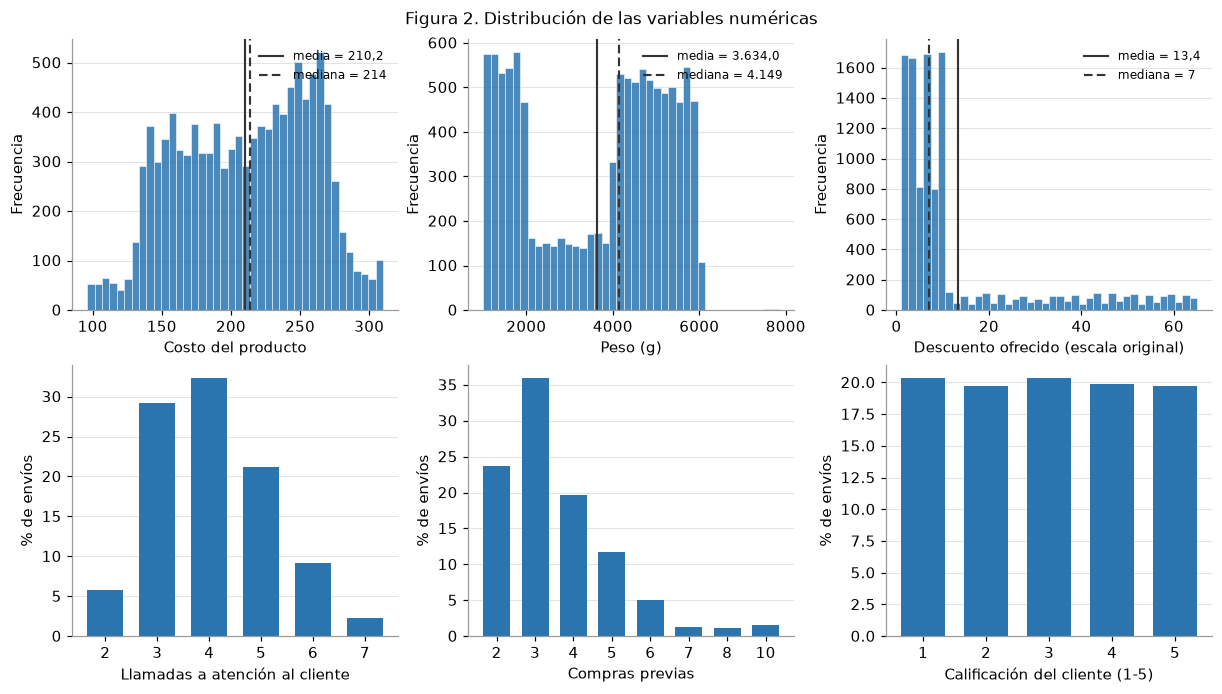

Envíos con peso entre 2.000 y 3.999 g: 1,790 (16.3%)
Envíos con descuento mayor a 10: 2,647 (24.1%)


In [9]:
CONTINUAS = [
    ("Cost_of_the_Product", "Costo del producto"),
    ("Weight_in_gms", "Peso (g)"),
    ("Discount_offered", "Descuento ofrecido (escala original)"),
]
DISCRETAS = [
    ("Customer_care_calls", "Llamadas a atención al cliente"),
    ("Prior_purchases", "Compras previas"),
    ("Customer_rating", "Calificación del cliente (1-5)"),
]

fig, ejes = plt.subplots(2, 3, figsize=(11, 6.2), layout="constrained")

# Fila superior: histogramas con media (línea continua) y mediana (discontinua).
for ax, (variable, etiqueta) in zip(ejes[0], CONTINUAS):
    serie = df_original[variable]
    ax.hist(serie, bins=40, color=COLOR_SERIE, alpha=0.85,
            edgecolor="white", linewidth=0.4)
    ax.axvline(serie.mean(), color="#333333", lw=1.4,
               label=f"media = {formato_es(serie.mean())}")
    ax.axvline(serie.median(), color="#333333", lw=1.4, ls=(0, (4, 2)),
               label=f"mediana = {formato_es(serie.median(), 0)}")
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(axis="x", visible=False)

# Fila inferior: frecuencias de las variables discretas.
for ax, (variable, etiqueta) in zip(ejes[1], DISCRETAS):
    conteos = df_original[variable].value_counts().sort_index()
    porcentajes = conteos / conteos.sum() * 100
    ax.bar(conteos.index.astype(str), porcentajes, color=COLOR_SERIE, width=0.7)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("% de envíos")
    ax.grid(axis="x", visible=False)

fig.suptitle("Figura 2. Distribución de las variables numéricas", fontsize=11)
guardar_figura(fig, "fig02_distribucion_numericas")
plt.show()

# Bimodalidad del peso: proporción de envíos en el tramo central 2.000-3.999 g.
tramo_central = df_original["Weight_in_gms"].between(2000, 3999)
print(f"Envíos con peso entre 2.000 y 3.999 g: {tramo_central.sum():,} "
      f"({tramo_central.mean():.1%})")
print(f"Envíos con descuento mayor a 10: {(df_original['Discount_offered'] > 10).sum():,} "
      f"({(df_original['Discount_offered'] > 10).mean():.1%})")

### Interpretación de las distribuciones

**Peso.** La distribución es bimodal: se concentra entre 1.000 y 2.000 g y entre 4.000 y 6.000 g, con un tramo intermedio de 2.000 a 3.999 g que reúne solo 1.790 envíos (16,3 %). En este caso, la media (3.634 g) cae precisamente en la zona de menor densidad y no representa un envío típico. La sección 2.6 muestra que ese tramo intermedio se ubica casi por completo en un bloque específico del archivo.

**Descuento.** La mayoría de los envíos tiene descuentos entre 1 y 10, con una distribución aproximadamente uniforme en ese rango. Sobre 10 aparece una meseta baja y extensa hasta 65 que contiene 2.647 envíos (24,1 %). Esta forma no corresponde a una cola continua, sino a dos regímenes distintos, lo que explica que la media (13,4) casi duplique a la mediana (7).

**Costo.** Varía entre 96 y 310, con mayor densidad entre 140 y 280 y sin valores aislados. La cercanía entre media y mediana es consistente con su baja asimetría.

**Variables discretas.** Las llamadas a atención al cliente se concentran entre 3 y 5. Las compras previas se acumulan en 2 y 3 y disminuyen con rapidez. La calificación del cliente es prácticamente uniforme: cada valor de 1 a 5 reúne cerca del 20 % de los envíos. Esta regularidad no permite determinar si el origen de los datos es real o sintético.

### 2.4. Distribución de las variables categóricas

Para las variables cualitativas se calculan frecuencias absolutas y relativas, y se representan con barras. Las categorías de importancia se presentan en su orden natural (baja, media, alta); las demás, en orden alfabético. Se conservan los códigos originales del archivo para mantener la trazabilidad con los datos.

Tabla 4. Frecuencias absolutas y relativas de las variables categóricas


,variable,categoria,frecuencia,porcentaje
0,Warehouse_block,A,1833,16.67
1,Warehouse_block,B,1833,16.67
2,Warehouse_block,C,1833,16.67
3,Warehouse_block,D,1834,16.67
4,Warehouse_block,F,3666,33.33
5,Mode_of_Shipment,Flight,1777,16.16
6,Mode_of_Shipment,Road,1760,16.00
7,Mode_of_Shipment,Ship,7462,67.84
8,Product_importance,low,5297,48.16
9,Product_importance,medium,4754,43.22


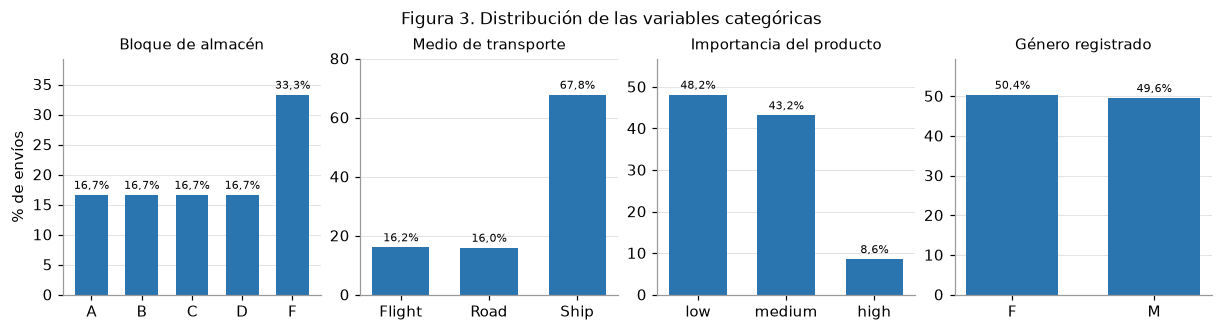

In [10]:
CATEGORICAS = [
    ("Warehouse_block", "Bloque de almacén"),
    ("Mode_of_Shipment", "Medio de transporte"),
    ("Product_importance", "Importancia del producto"),
    ("Gender", "Género registrado"),
]
ORDEN_IMPORTANCIA = ["low", "medium", "high"]


def frecuencias_categoricas(datos, variables):
    """Frecuencias absolutas y relativas de cada variable categórica."""
    partes = []
    for variable, _ in variables:
        conteos = datos[variable].value_counts()
        if variable == "Product_importance":
            conteos = conteos.reindex(ORDEN_IMPORTANCIA)
        else:
            conteos = conteos.sort_index()
        partes.append(pd.DataFrame({
            "variable": variable,
            "categoria": conteos.index,
            "frecuencia": conteos.to_numpy(),
            "porcentaje": conteos.to_numpy() / len(datos) * 100,
        }))
    return pd.concat(partes, ignore_index=True)


tabla_categoricas = frecuencias_categoricas(df_original, CATEGORICAS)
guardar_tabla(tabla_categoricas, "tab04_frecuencias_categoricas", index=False)
print("Tabla 4. Frecuencias absolutas y relativas de las variables categóricas")
display(tabla_categoricas.round({"porcentaje": 2}))

fig, ejes = plt.subplots(1, 4, figsize=(11, 2.9), layout="constrained")
for ax, (variable, etiqueta) in zip(ejes, CATEGORICAS):
    sub = tabla_categoricas[tabla_categoricas["variable"] == variable]
    barras = ax.bar(sub["categoria"].astype(str), sub["porcentaje"],
                    color=COLOR_SERIE, width=0.65)
    ax.bar_label(barras, labels=[f"{formato_es(p)}%" for p in sub["porcentaje"]],
                 fontsize=7.5, padding=2)
    ax.set_title(etiqueta)
    ax.set_ylim(0, sub["porcentaje"].max() * 1.18)
    ax.set_ylabel("% de envíos" if ax is ejes[0] else "")
    ax.grid(axis="x", visible=False)

fig.suptitle("Figura 3. Distribución de las variables categóricas", fontsize=11)
guardar_figura(fig, "fig03_distribucion_categoricas")
plt.show()

### Interpretación de las variables categóricas

El transporte marítimo (`Ship`) concentra el 67,8 % de los envíos; el aéreo y el terrestre se reparten el resto casi por igual (16,2 % y 16,0 %). El bloque de almacén F reúne aproximadamente un tercio de los registros y los bloques A a D, aproximadamente un sexto cada uno. Esta distribución y la ausencia del código E no permiten inferir cómo se construyó el archivo. La importancia del producto es mayoritariamente baja (48,2 %) o media (43,2 %), y solo el 8,6 % corresponde a productos de importancia alta. El género registrado se distribuye en partes casi iguales.

Para el análisis inferencial, la baja frecuencia de la categoría alta (948 envíos) sigue siendo suficiente para estimar su tasa de retraso con precisión razonable, como se verifica en la sección 4.

### 2.5. Análisis bivariado

Se examina la relación de cada variable con el cumplimiento del plazo y entre las variables explicativas. Se utiliza la correlación de Spearman porque varias variables son asimétricas, bimodales u ordinales, y Spearman solo supone una relación monótona; la correlación de Pearson se reporta como referencia. Con la variable objetivo binaria, Pearson equivale a la correlación punto-biserial.

Una correlación cercana a cero no descarta relaciones no lineales, y una correlación alta no implica causalidad; por eso el análisis se complementa con tasas de retraso por categoría y comparaciones gráficas entre grupos.

Tabla 5. Correlación de cada variable numérica con el retraso (1 = fuera de plazo)


,pearson_punto_biserial,spearman
Discount_offered,0.397,0.335
Weight_in_gms,-0.269,-0.266
Prior_purchases,-0.056,-0.075
Cost_of_the_Product,-0.074,-0.072
Customer_care_calls,-0.067,-0.064
Customer_rating,0.013,0.013


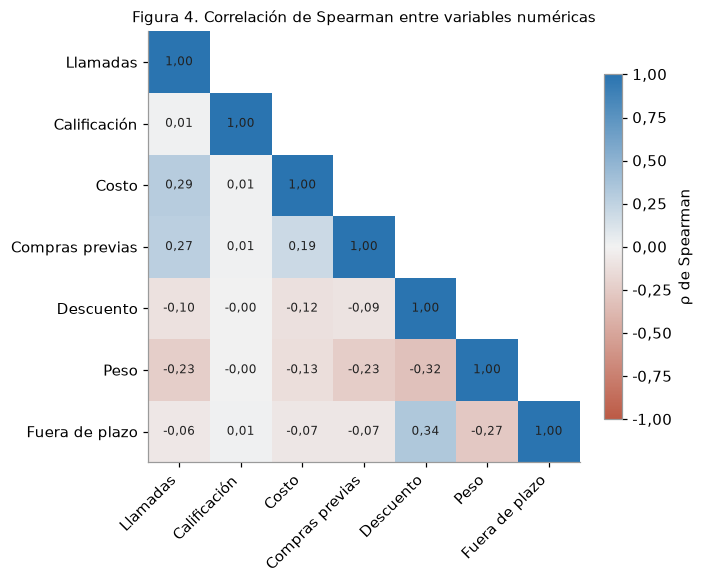

In [11]:
# Correlaciones entre variables numéricas y con el indicador de retraso.
VARIABLES_CORRELACION = [
    "Customer_care_calls", "Customer_rating", "Cost_of_the_Product",
    "Prior_purchases", "Discount_offered", "Weight_in_gms", OBJETIVO,
]
ETIQUETAS_CORTAS = {
    "Customer_care_calls": "Llamadas",
    "Customer_rating": "Calificación",
    "Cost_of_the_Product": "Costo",
    "Prior_purchases": "Compras previas",
    "Discount_offered": "Descuento",
    "Weight_in_gms": "Peso",
    OBJETIVO: "Fuera de plazo",
}

corr_spearman = df_original[VARIABLES_CORRELACION].corr(method="spearman")
corr_pearson = df_original[VARIABLES_CORRELACION].corr(method="pearson")

# Tabla 5: asociación de cada variable con el retraso. Con una variable
# binaria, Pearson equivale a la correlación punto-biserial.
correlacion_objetivo = pd.DataFrame({
    "pearson_punto_biserial": corr_pearson[OBJETIVO].drop(OBJETIVO),
    "spearman": corr_spearman[OBJETIVO].drop(OBJETIVO),
}).sort_values("spearman", key=np.abs, ascending=False)
guardar_tabla(correlacion_objetivo, "tab05_correlacion_objetivo")
print("Tabla 5. Correlación de cada variable numérica con el retraso (1 = fuera de plazo)")
display(correlacion_objetivo.round(3))

# Figura 4: matriz de Spearman (triángulo inferior).
mapa = LinearSegmentedColormap.from_list(
    "divergente", [COLOR_FUERA_PLAZO, "#F2F2F2", COLOR_A_TIEMPO])
matriz = corr_spearman.rename(index=ETIQUETAS_CORTAS, columns=ETIQUETAS_CORTAS)
mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1)
valores = np.ma.masked_array(matriz.to_numpy(), mask=mascara)

fig, ax = plt.subplots(figsize=(6.4, 5.2), layout="constrained")
imagen = ax.imshow(valores, cmap=mapa, vmin=-1, vmax=1)
ax.set_xticks(range(len(matriz)), matriz.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matriz)), matriz.index)
ax.grid(False)
for i in range(len(matriz)):
    for j in range(i + 1):
        ax.text(j, i, f"{matriz.iat[i, j]:.2f}".replace(".", ","),
                ha="center", va="center", fontsize=8, color="#222222")
barra = fig.colorbar(imagen, ax=ax, shrink=0.8, label="ρ de Spearman")
barra.ax.yaxis.set_major_formatter(lambda valor, _: formato_es(valor, 2))
ax.set_title("Figura 4. Correlación de Spearman entre variables numéricas")
guardar_figura(fig, "fig04_correlacion_spearman")
plt.show()

### Interpretación de las correlaciones

Solo dos variables muestran una asociación apreciable con el retraso. El **descuento** se asocia positivamente (ρ = 0,335; Pearson 0,397): los envíos con mayor descuento tienden a llegar fuera de plazo. El **peso** se asocia negativamente (ρ = −0,266): los envíos más livianos tienden a retrasarse. Las demás variables presentan |ρ| < 0,08, y la calificación del cliente presenta una correlación de Spearman cercana a cero con el resultado (ρ = 0,013).

Entre las variables explicativas, las correlaciones son débiles o moderadas. Las más altas relacionan el descuento con el peso (ρ = −0,316) y las llamadas con el costo (0,294) y con las compras previas (0,273). No se observan correlaciones altas por pares; esto no descarta multicolinealidad entre combinaciones de variables en un modelo posterior.

Estas correlaciones deben leerse con cautela. La sección 2.6 muestra que las asociaciones del descuento y del peso con el retraso se concentran en un bloque del archivo.

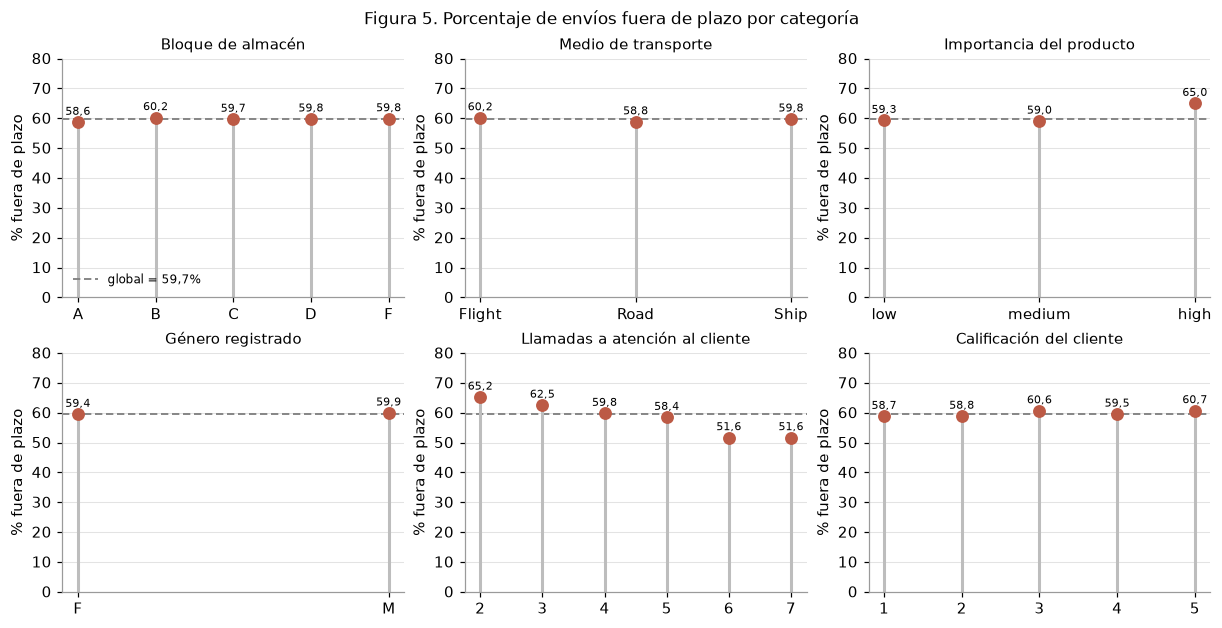

Tabla 6. Porcentaje de envíos fuera de plazo por categoría


,variable,categoria,n,tasa
0,Warehouse_block,A,1833,58.65
1,Warehouse_block,B,1833,60.23
2,Warehouse_block,C,1833,59.68
3,Warehouse_block,D,1834,59.76
4,Warehouse_block,F,3666,59.85
5,Mode_of_Shipment,Flight,1777,60.16
6,Mode_of_Shipment,Road,1760,58.81
7,Mode_of_Shipment,Ship,7462,59.76
8,Product_importance,low,5297,59.28
9,Product_importance,medium,4754,59.05


In [12]:
# Tasa de retraso por categoría de cada variable cualitativa u ordinal.
TASA_GLOBAL = df_original[OBJETIVO].mean() * 100

VARIABLES_TASA = [
    ("Warehouse_block", "Bloque de almacén", None),
    ("Mode_of_Shipment", "Medio de transporte", None),
    ("Product_importance", "Importancia del producto", ORDEN_IMPORTANCIA),
    ("Gender", "Género registrado", None),
    ("Customer_care_calls", "Llamadas a atención al cliente", None),
    ("Customer_rating", "Calificación del cliente", None),
]


def tasa_por_categoria(datos, variable, orden=None):
    """Número de envíos y porcentaje fuera de plazo por categoría."""
    resumen = datos.groupby(variable)[OBJETIVO].agg(n="size", tasa="mean")
    resumen["tasa"] *= 100
    return resumen.reindex(orden) if orden else resumen.sort_index()


partes = []
fig, ejes = plt.subplots(2, 3, figsize=(11, 5.6), layout="constrained")
for ax, (variable, etiqueta, orden) in zip(ejes.ravel(), VARIABLES_TASA):
    resumen = tasa_por_categoria(df_original, variable, orden)
    partes.append(resumen.reset_index(names="categoria").assign(variable=variable))
    x = np.arange(len(resumen))
    ax.axhline(TASA_GLOBAL, color=COLOR_REFERENCIA, ls=(0, (4, 2)), lw=1.2,
               label=f"global = {formato_es(TASA_GLOBAL)}%")
    ax.vlines(x, 0, resumen["tasa"], color="#BDBDBD", lw=2)
    ax.scatter(x, resumen["tasa"], color=COLOR_FUERA_PLAZO, s=55, zorder=3)
    for xi, yi in zip(x, resumen["tasa"]):
        ax.text(xi, yi + 2.5, formato_es(yi), ha="center", fontsize=7.5)
    ax.set_xticks(x, resumen.index.astype(str))
    ax.set_ylim(0, 80)
    ax.set_title(etiqueta)
    ax.set_ylabel("% fuera de plazo")
    ax.grid(axis="x", visible=False)
ejes[0, 0].legend(fontsize=8, loc="lower left")
fig.suptitle("Figura 5. Porcentaje de envíos fuera de plazo por categoría", fontsize=11)
guardar_figura(fig, "fig05_tasa_por_categoria")
plt.show()

tabla_tasas = pd.concat(partes, ignore_index=True)[["variable", "categoria", "n", "tasa"]]
guardar_tabla(tabla_tasas, "tab06_tasa_por_categoria", index=False)
print("Tabla 6. Porcentaje de envíos fuera de plazo por categoría")
display(tabla_tasas.round({"tasa": 2}))

### Interpretación de las tasas por categoría

El porcentaje global de envíos fuera de plazo es 59,7 % (línea discontinua). El bloque de almacén (58,6 %–60,2 %), el medio de transporte (58,8 %–60,2 %), el género (59,4 % y 59,9 %) y la calificación (58,7 %–60,7 %) se mantienen en torno a ese valor: las diferencias son de uno o dos puntos y no sugieren asociación.

Destacan dos patrones. Los productos de **importancia alta** presentan un 65,0 % de retraso, unos seis puntos sobre la importancia baja (59,3 %) y media (59,0 %); este contraste se evalúa en la prueba 2. Las **llamadas a atención al cliente** muestran un gradiente descendente, desde 65,2 % con dos llamadas hasta 51,6 % con seis o siete. En apariencia, más llamadas se asocian con menos retraso, lo que resulta contraintuitivo; la sección 4.4 muestra que este gradiente se invierte al excluir el bloque inicial del archivo.

Tabla 7. Media, mediana y desviación estándar por estado de entrega


Reached.on.Time_Y.N              A tiempo  Fuera de plazo
variable            estadistico                          
Weight_in_gms       mean          4168.67         3272.64
                    median        4674.00         3231.00
                    std           1573.95         1576.15
Discount_offered    mean             5.55           18.66
                    median           6.00            9.00
                    std              2.88           19.11
Cost_of_the_Product mean           214.50          207.29
                    median         222.00          209.00
                    std             47.76           48.05
Customer_care_calls mean             4.15            3.99
                    median           4.00            4.00
                    std              1.16            1.12
Prior_purchases     mean             3.67            3.50
                    median           3.00            3.00
                    std              1.53            1.52

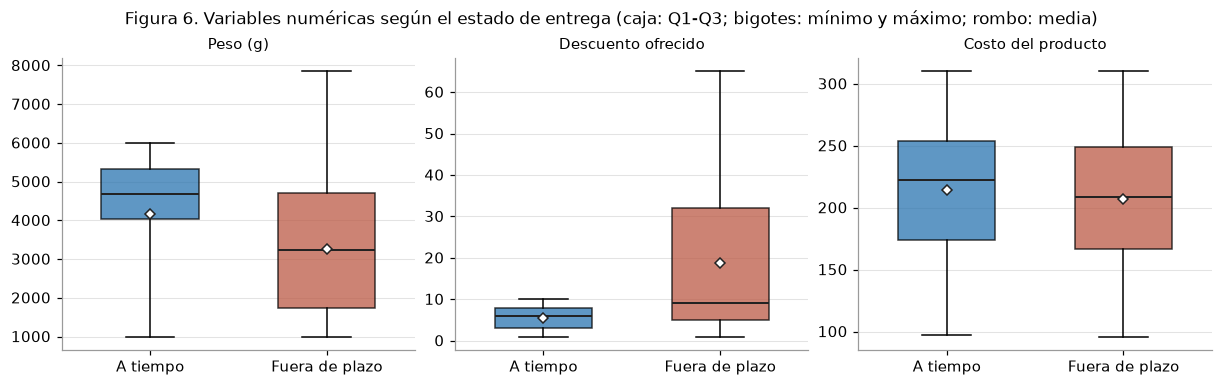

In [13]:
# Comparación de las variables numéricas entre envíos a tiempo y fuera de plazo.
COMPARAR = [
    ("Weight_in_gms", "Peso (g)"),
    ("Discount_offered", "Descuento ofrecido"),
    ("Cost_of_the_Product", "Costo del producto"),
]

resumen_grupos = (
    df_original
    .groupby(OBJETIVO)[[v for v, _ in COMPARAR] + ["Customer_care_calls", "Prior_purchases"]]
    .agg(["mean", "median", "std"])
    .T
    .rename(columns=ETIQUETAS_ESTADO)
)
resumen_grupos.index.names = ["variable", "estadistico"]
guardar_tabla(resumen_grupos, "tab07_numericas_por_grupo")
print("Tabla 7. Media, mediana y desviación estándar por estado de entrega")
display(resumen_grupos.round(2))

fig, ejes = plt.subplots(1, 3, figsize=(11, 3.4), layout="constrained")
for ax, (variable, etiqueta) in zip(ejes, COMPARAR):
    grupos = [df_original.loc[df_original[OBJETIVO] == k, variable] for k in (0, 1)]
    cajas = ax.boxplot(
        grupos, tick_labels=list(ETIQUETAS_ESTADO.values()), widths=0.55,
        whis=(0, 100),
        patch_artist=True, showmeans=True,
        meanprops=dict(marker="D", markerfacecolor="white",
                       markeredgecolor="#222222", markersize=5),
        medianprops=dict(color="#222222", lw=1.3),
        flierprops=dict(marker="o", markersize=2, alpha=0.3,
                        markerfacecolor=COLOR_REFERENCIA, markeredgecolor="none"),
    )
    for caja, k in zip(cajas["boxes"], (0, 1)):
        caja.set_facecolor(COLORES_ESTADO[k])
        caja.set_alpha(0.75)
    ax.set_title(etiqueta)
    ax.grid(axis="x", visible=False)
fig.suptitle("Figura 6. Variables numéricas según el estado de entrega "
             "(caja: Q1-Q3; bigotes: mínimo y máximo; rombo: media)",
             fontsize=11)
guardar_figura(fig, "fig06_numericas_por_grupo")
plt.show()

### Interpretación de la comparación entre grupos

Los envíos fuera de plazo pesan en promedio 3.273 g, frente a 4.169 g de los envíos a tiempo; las medianas (3.231 g y 4.674 g) confirman la diferencia. En el descuento, la media del grupo fuera de plazo (18,7) triplica la del grupo a tiempo (5,5), y su desviación estándar es seis veces mayor (19,1 frente a 2,9): todos los descuentos altos se encuentran entre los envíos retrasados. El costo difiere en unas 7 unidades (207,3 frente a 214,5), una diferencia pequeña frente a su dispersión.

El hallazgo más llamativo es que el grupo a tiempo no tiene envíos con descuento superior a 10. Una frontera tan nítida no es habitual en procesos logísticos reales y motiva la revisión de la estructura del archivo en la sección siguiente.

### 2.6. Estructura del archivo según el identificador

Las secciones anteriores detectaron tres señales atípicas: un tramo de peso casi vacío, una meseta de descuentos altos y una frontera nítida en el descuento igual a 10. Se examina si estas señales se relacionan con la posición del registro en el archivo, usando `ID` como variable de diagnóstico (no como predictor).

El punto de corte se define como el último `ID` de la racha inicial ininterrumpida de envíos fuera de plazo. Como descripción adicional del mismo archivo, se examina el último `ID` con descuento mayor a 10.

In [14]:
# Punto de corte: último ID de la racha inicial ininterrumpida de envíos fuera de plazo.
primer_a_tiempo = df_original.loc[df_original[OBJETIVO] == 0, "ID"].min()
ID_CORTE = int(primer_a_tiempo - 1)

# Corroboración con un criterio que no usa la variable objetivo:
# hasta qué ID aparecen descuentos mayores a 10.
ultimo_id_descuento_alto = int(df_original.loc[df_original["Discount_offered"] > 10, "ID"].max())
descuento_max_a_tiempo = int(df_original.loc[df_original[OBJETIVO] == 0, "Discount_offered"].max())

print(f"Primer envío a tiempo en el archivo: ID {primer_a_tiempo}")
print(f"Punto de corte (ID_CORTE): {ID_CORTE}")
print(f"Último ID con descuento > 10: {ultimo_id_descuento_alto}")
print(f"Descuento máximo entre envíos a tiempo: {descuento_max_a_tiempo}")

bloque = np.where(df_original["ID"] <= ID_CORTE,
                  f"ID ≤ {ID_CORTE:,}".replace(",", "."),
                  f"ID > {ID_CORTE:,}".replace(",", "."))

comparacion_bloques = df_original.groupby(bloque).agg(
    n=("ID", "size"),
    pct_fuera_plazo=(OBJETIVO, lambda s: s.mean() * 100),
    descuento_medio=("Discount_offered", "mean"),
    descuento_maximo=("Discount_offered", "max"),
    pct_descuento_mayor_10=("Discount_offered", lambda s: (s > 10).mean() * 100),
    peso_medio=("Weight_in_gms", "mean"),
    pct_peso_2000_3999=("Weight_in_gms", lambda s: s.between(2000, 3999).mean() * 100),
    costo_medio=("Cost_of_the_Product", "mean"),
).T
guardar_tabla(comparacion_bloques, "tab08_comparacion_bloques")
print("\nTabla 8. Comparación entre el bloque inicial y el resto del archivo")
display(comparacion_bloques.round(2))

# Reglas deterministas observadas.
reglas = pd.DataFrame({
    "condicion": ["Descuento > 10", "Descuento ≤ 10",
                  "Peso 2.000-3.999 g", "Peso fuera de 2.000-3.999 g"],
    "n": [
        (df_original["Discount_offered"] > 10).sum(),
        (df_original["Discount_offered"] <= 10).sum(),
        tramo_central.sum(),
        (~tramo_central).sum(),
    ],
    "pct_fuera_plazo": [
        df_original.loc[df_original["Discount_offered"] > 10, OBJETIVO].mean() * 100,
        df_original.loc[df_original["Discount_offered"] <= 10, OBJETIVO].mean() * 100,
        df_original.loc[tramo_central, OBJETIVO].mean() * 100,
        df_original.loc[~tramo_central, OBJETIVO].mean() * 100,
    ],
})
guardar_tabla(reglas, "tab09_reglas_frontera", index=False)
print("Tabla 9. Porcentaje fuera de plazo según umbrales de descuento y peso")
display(reglas.round(2))

Primer envío a tiempo en el archivo: ID 3136
Punto de corte (ID_CORTE): 3135
Último ID con descuento > 10: 3134
Descuento máximo entre envíos a tiempo: 10

Tabla 8. Comparación entre el bloque inicial y el resto del archivo


,ID > 3.135,ID ≤ 3.135
n,7864.00,3135.00
pct_fuera_plazo,43.59,100.00
descuento_medio,5.52,33.07
descuento_maximo,10.00,65.00
pct_descuento_mayor_10,0.00,84.43
peso_medio,4139.63,2365.72
pct_peso_2000_3999,0.04,57.00
costo_medio,215.86,196.00


Tabla 9. Porcentaje fuera de plazo según umbrales de descuento y peso


,condicion,n,pct_fuera_plazo
0,Descuento > 10,2647,100.00
1,Descuento ≤ 10,8352,46.89
2,Peso 2.000-3.999 g,1790,99.89
3,Peso fuera de 2.000-3.999 g,9209,51.85


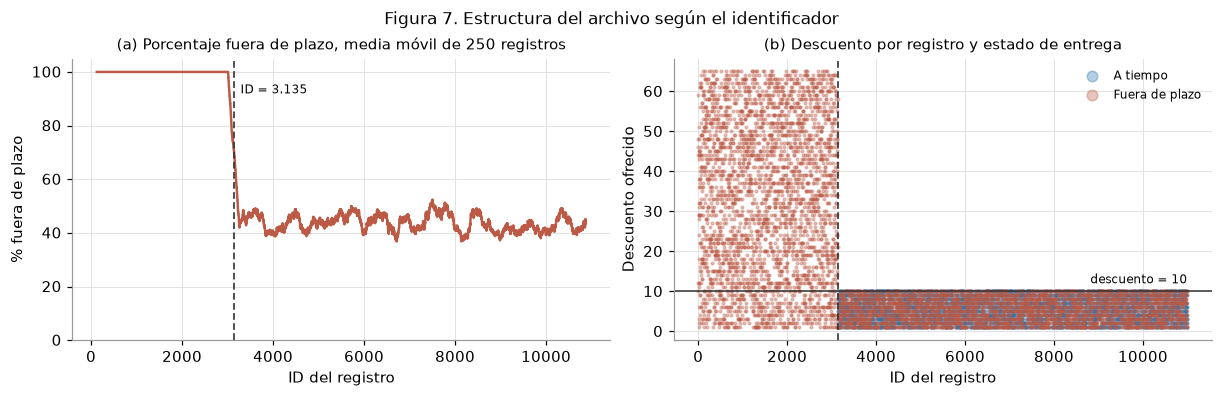

Subconjunto de sensibilidad (ID > 3135): 7,864 registros (71.5% del total)


In [15]:
# Figura 7: evolución del retraso y del descuento a lo largo del archivo.
VENTANA = 250
tasa_movil = df_original[OBJETIVO].rolling(VENTANA, center=True).mean() * 100

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")

ax = ejes[0]
ax.plot(df_original["ID"], tasa_movil, color=COLOR_FUERA_PLAZO, lw=1.6)
ax.axvline(ID_CORTE, color="#333333", ls=(0, (4, 2)), lw=1.1)
ax.text(ID_CORTE + 150, 92, f"ID = {ID_CORTE:,}".replace(",", "."), fontsize=8)
ax.set_ylim(0, 105)
ax.set_xlabel("ID del registro")
ax.set_ylabel("% fuera de plazo")
ax.set_title(f"(a) Porcentaje fuera de plazo, media móvil de {VENTANA} registros")

ax = ejes[1]
for k in (0, 1):
    sub = df_original[df_original[OBJETIVO] == k]
    ax.scatter(sub["ID"], sub["Discount_offered"], s=3, alpha=0.35,
               color=COLORES_ESTADO[k], label=ETIQUETAS_ESTADO[k], rasterized=True)
ax.axhline(10, color="#333333", lw=1.0)
ax.axvline(ID_CORTE, color="#333333", ls=(0, (4, 2)), lw=1.1)
ax.text(10999, 12, "descuento = 10", ha="right", fontsize=8)
ax.set_xlabel("ID del registro")
ax.set_ylabel("Descuento ofrecido")
ax.set_title("(b) Descuento por registro y estado de entrega")
ax.legend(markerscale=4, fontsize=8, loc="upper right")

fig.suptitle("Figura 7. Estructura del archivo según el identificador", fontsize=11)
guardar_figura(fig, "fig07_estructura_por_id")
plt.show()

# Subconjunto para el análisis de sensibilidad.
df_sensibilidad = df_original[df_original["ID"] > ID_CORTE].copy()
print(f"Subconjunto de sensibilidad (ID > {ID_CORTE}): {len(df_sensibilidad):,} registros "
      f"({len(df_sensibilidad) / len(df_original):.1%} del total)")

### Interpretación de la estructura del archivo

El archivo contiene **dos regímenes con una frontera abrupta en el ID 3.135**:

- En el **bloque inicial** (ID ≤ 3.135; 3.135 registros), el 100 % de los envíos llegó fuera de plazo. Concentra el 84,4 % de sus registros con descuento mayor a 10 (media 33,1, máximo 65) y el 57,0 % con peso entre 2.000 y 3.999 g (peso medio 2.366 g).
- En el **resto del archivo** (ID > 3.135; 7.864 registros), el 43,6 % llegó fuera de plazo. El descuento nunca supera 10 (media 5,5) y el tramo de 2.000–3.999 g está prácticamente vacío (0,04 %; peso medio 4.140 g).

Como evidencia descriptiva adicional, el último descuento mayor a 10 aparece en el ID 3.134, contiguo al corte. Además, los umbrales se comportan como reglas deterministas: con descuento mayor a 10, el 100 % de los envíos está fuera de plazo; con peso entre 2.000 y 3.999 g, el 99,9 %. La Figura 7 muestra que, después del corte, el porcentaje fuera de plazo se estabiliza en torno al 43 % sin ninguna tendencia.

### Justificación del análisis de sensibilidad

1. **Supuesto de población única.** Los intervalos y las pruebas de las secciones 3 y 4 suponen una muestra independiente de una sola población. Si el archivo combina dos subpoblaciones, una estimación conjunta mezcla la diferencia *entre bloques* con la asociación *dentro* de cada bloque y puede producir asociaciones aparentes o invertidas, como en la paradoja de Simpson.
2. **Plausibilidad del mecanismo.** Un umbral que determina el resultado sin excepciones no es habitual en logística. Sugiere un artefacto en la construcción del conjunto, cuyo origen no está documentado. También admite una interpretación más delicada: si el descuento se otorgó como compensación por el retraso, sería un registro posterior al resultado y no podría utilizarse para explicarlo, lo que constituye una fuga de información.
3. **Consecuencia para la decisión.** Si la empresa restringiera descuentos o reasignara recursos según una asociación producida por la estructura del archivo, no habría evidencia causal suficiente para anticipar que la intervención reduciría los retrasos. Identificar qué conclusiones dependen del bloque es parte de decidir bajo incertidumbre.
4. **Continuidad del proyecto.** La Sumativa 2 exige evaluar la sensibilidad de los resultados a observaciones influyentes, y la regresión logística de la Sumativa 3 enfrentaría una separación casi perfecta si se incluye el descuento sin tratamiento.

### Salvaguardas metodológicas

- **El análisis principal se realiza sobre los 10.999 registros**, como exige la evaluación. El subconjunto ID > 3.135 se analiza de forma complementaria y no reemplaza ningún resultado.
- **El punto de corte se identificó después de observar los datos.** Por ello, la comparación es exploratoria y no confirmatoria. El patrón del descuento se observó en los mismos datos y no constituye una validación independiente del corte.
- **El subconjunto no se usa para estimar el porcentaje poblacional de retrasos.** Como el corte se definió en parte con la variable objetivo, la exclusión de una racha compuesta solo por retrasos reduce la proporción observada por construcción; no conocemos la proporción poblacional ni el sesgo respecto de ella. El subconjunto solo se usa para evaluar si las asociaciones persisten.
- **En el subconjunto, el descuento solo varía entre 1 y 10.** Esta restricción de rango reduce por sí misma la capacidad de detectar una asociación, lo que se considera al interpretar sus resultados.

## 3. Estimación de parámetros

Se estiman con un nivel de confianza del 95 % la proporción de envíos fuera de plazo y las medias de tres variables numéricas: costo, peso y descuento. El costo representa el valor del producto despachado; el peso y el descuento son las variables con mayor asociación con el retraso en el análisis exploratorio.

**Métodos.** Para las medias se utiliza el intervalo basado en la aproximación normal,

$$\bar{x} \pm z_{0{,}975}\,\frac{s}{\sqrt{n}},$$

como aproximación de gran muestra bajo independencia y condiciones del Teorema Central del Límite. El tamaño n = 10.999 favorece la aproximación, pero no corrige sesgos de selección ni demuestra independencia. Para la proporción se usa la aproximación normal de Wald,

$$\hat{p} \pm z_{0{,}975}\sqrt{\frac{\hat{p}(1-\hat{p})}{n}},$$

cuya condición de conteos grandes se satisface porque n·p̂ y n·(1 − p̂) superan ampliamente 10. Ambos son los procedimientos vistos en el curso.

*Complemento (no evaluado):* el intervalo de Wilson ofrece mejor cobertura cuando la proporción es extrema o la muestra es pequeña. Se reporta para verificar que, con este tamaño muestral, ambos métodos producen límites muy próximos, aunque no idénticos.

In [16]:
def ic_media_normal(serie, z=Z_CRITICO):
    """IC para la media con aproximación normal: x̄ ± z · s/√n."""
    serie = pd.Series(serie).dropna()
    n = len(serie)
    media = serie.mean()
    ee = serie.std(ddof=1) / np.sqrt(n)
    return {"estimacion": media, "error_estandar": ee,
            "ic_inferior": media - z * ee, "ic_superior": media + z * ee, "n": n}


def ic_proporcion_wald(exitos, n, z=Z_CRITICO):
    """IC de Wald para una proporción: p̂ ± z · √(p̂(1-p̂)/n)."""
    p = exitos / n
    ee = np.sqrt(p * (1 - p) / n)
    return {"estimacion": p, "error_estandar": ee,
            "ic_inferior": p - z * ee, "ic_superior": p + z * ee, "n": n}


def ic_proporcion_wilson(exitos, n, z=Z_CRITICO):
    """IC de Wilson (complemento): mejor cobertura con p extremas o n pequeños."""
    p = exitos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    semiancho = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return {"estimacion": p, "error_estandar": np.nan,
            "ic_inferior": centro - semiancho, "ic_superior": centro + semiancho, "n": n}


n_total = len(df_original)
retrasos = int(df_original[OBJETIVO].sum())

filas = [
    {"parametro": "Proporción de envíos fuera de plazo", "metodo": "Normal (Wald)",
     **ic_proporcion_wald(retrasos, n_total)},
    {"parametro": "Proporción de envíos fuera de plazo", "metodo": "Wilson (complemento)",
     **ic_proporcion_wilson(retrasos, n_total)},
    {"parametro": "Costo medio del producto", "metodo": "Normal (TCL)",
     **ic_media_normal(df_original["Cost_of_the_Product"])},
    {"parametro": "Peso medio (g)", "metodo": "Normal (TCL)",
     **ic_media_normal(df_original["Weight_in_gms"])},
    {"parametro": "Descuento medio", "metodo": "Normal (TCL)",
     **ic_media_normal(df_original["Discount_offered"])},
]
tabla_ic = pd.DataFrame(filas)
tabla_ic["semiancho"] = (tabla_ic["ic_superior"] - tabla_ic["ic_inferior"]) / 2
tabla_ic["semiancho_relativo_pct"] = tabla_ic["semiancho"] / tabla_ic["estimacion"] * 100

guardar_tabla(tabla_ic, "tab10_intervalos_confianza", index=False)
print("Tabla 10. Estimación puntual e intervalos de confianza al 95 %")
display(tabla_ic.round(4))

# Medianas como referencia robusta para las variables asimétricas o bimodales.
print("\nMedianas de referencia:")
for variable in ["Cost_of_the_Product", "Weight_in_gms", "Discount_offered"]:
    print(f"  {variable}: {df_original[variable].median():,.0f}")

Tabla 10. Estimación puntual e intervalos de confianza al 95 %


,parametro,metodo,estimacion,error_estandar,ic_inferior,ic_superior,n,semiancho,semiancho_relativo_pct
0,Proporción de envíos fuera de plazo,Normal (Wald),0.5967,0.0047,0.5875,0.6059,10999,0.0092,1.5364
1,Proporción de envíos fuera de plazo,Wilson (complemento),0.5967,NaN,0.5875,0.6058,10999,0.0092,1.5362
2,Costo medio del producto,Normal (TCL),210.1968,0.4583,209.2986,211.0951,10999,0.8982,0.4273
3,Peso medio (g),Normal (TCL),3634.0167,15.5934,3603.4542,3664.5793,10999,30.5625,0.8410
4,Descuento medio,Normal (TCL),13.3732,0.1545,13.0704,13.6761,10999,0.3029,2.2646



Medianas de referencia:
  Cost_of_the_Product: 214
  Weight_in_gms: 4,149
  Discount_offered: 7


### Interpretación de los intervalos

El intervalo de Wald obtenido para la proporción de envíos fuera de plazo es **[58,75 %; 60,59 %]** (estimación puntual 59,67 %). Los intervalos de Wald y Wilson son muy próximos, aunque no idénticos.

El costo medio se estima en **210,20** [209,30; 211,10], el peso medio en **3.634,0 g** [3.603,5; 3.664,6] y el descuento medio en **13,37** [13,07; 13,68]. Los intervalos son estrechos: su semiancho no supera el 2,3 % de la estimación, consecuencia directa del tamaño muestral.

**Interpretación correcta del nivel de confianza.** El 95 % describe el procedimiento: si se repitiera el muestreo muchas veces, aproximadamente el 95 % de los intervalos construidos contendría el parámetro, bajo los supuestos del procedimiento. No significa que exista un 95 % de probabilidad de que el parámetro esté en este intervalo particular.

### Limitaciones

- **Representatividad.** Los intervalos cuantifican solo el error de muestreo aleatorio. Si el archivo no es una muestra aleatoria de la población de envíos, su estrechez no protege contra sesgos. La sección 2.6 indica que la composición del archivo no es homogénea.
- **Media del peso.** El intervalo es válido para la media, pero la media se ubica en la zona de menor densidad de una distribución bimodal. Para describir un envío típico es más informativo reportar los dos grupos de peso o la mediana (4.149 g).
- **Media del descuento.** Está influida por la meseta de descuentos altos; la mediana (7) describe mejor el descuento habitual. Además, su unidad no está documentada.
- **Independencia.** El método supone observaciones independientes. La estructura por bloques sugiere que los registros podrían no ser intercambiables, supuesto que se examina a continuación.
- **Origen y alcance.** No se documentan la empresa, el período de observación ni el procedimiento de muestreo. No es posible asegurar representatividad ni generalizar estos resultados a cualquier operación logística.


In [17]:
# Sensibilidad de las estimaciones al bloque inicial del archivo.
filas = []
for variable, etiqueta in [("Cost_of_the_Product", "Costo medio del producto"),
                           ("Weight_in_gms", "Peso medio (g)"),
                           ("Discount_offered", "Descuento medio")]:
    completo = ic_media_normal(df_original[variable])
    reducido = ic_media_normal(df_sensibilidad[variable])
    filas.append({
        "parametro": etiqueta,
        "completo_estimacion": completo["estimacion"],
        "completo_ic_inferior": completo["ic_inferior"],
        "completo_ic_superior": completo["ic_superior"],
        "sensibilidad_estimacion": reducido["estimacion"],
        "sensibilidad_ic_inferior": reducido["ic_inferior"],
        "sensibilidad_ic_superior": reducido["ic_superior"],
        "cambio_relativo_pct": (reducido["estimacion"] / completo["estimacion"] - 1) * 100,
        "intervalos_se_solapan": (reducido["ic_inferior"] <= completo["ic_superior"])
                                 and (completo["ic_inferior"] <= reducido["ic_superior"]),
    })
sensibilidad_ic = pd.DataFrame(filas)
guardar_tabla(sensibilidad_ic, "tab11_sensibilidad_ic", index=False)
print(f"Tabla 11. Medias e IC 95 %: dataset completo frente a ID > {ID_CORTE}")
display(sensibilidad_ic.round(2))

Tabla 11. Medias e IC 95 %: dataset completo frente a ID > 3135


,parametro,completo_estimacion,completo_ic_inferior,completo_ic_superior,sensibilidad_estimacion,sensibilidad_ic_inferior,sensibilidad_ic_superior,cambio_relativo_pct,intervalos_se_solapan
0,Costo medio del producto,210.20,209.30,211.10,215.86,214.80,216.91,2.69,False
1,Peso medio (g),3634.02,3603.45,3664.58,4139.63,4104.65,4174.60,13.91,False
2,Descuento medio,13.37,13.07,13.68,5.52,5.46,5.58,-58.72,False


### Sensibilidad de las estimaciones

Al excluir el bloque inicial, el descuento medio cae un 58,7 % (de 13,37 a 5,52) y el peso medio aumenta un 13,9 % (de 3.634 a 4.140 g). El costo medio cambia un 2,7 %. En las tres variables, los intervalos del dataset completo y del subconjunto **no se solapan**.

Esto muestra que la principal incertidumbre de las estimaciones no proviene del error de muestreo, que es pequeño, sino de la composición del archivo. Un intervalo de ±0,3 unidades para el descuento medio transmite una precisión que no se sostiene si la proporción de registros de cada bloque fuera distinta en la población. Esta limitación se traslada a la Sumativa 2, donde se compararán estos intervalos con intervalos bootstrap.

## 4. Pruebas de hipótesis

Se aplican dos pruebas principales, una para cada tipo de variable, y pruebas complementarias que alimentan la Formativa 1 y el análisis de sensibilidad.

**Nivel de significancia.** Se fija α = 0,05, nivel convencional que fija una tasa nominal de error tipo I del 5 % para cada contraste bajo sus supuestos. No equilibra automáticamente los errores de tipo I y II; la potencia depende también del tamaño de muestra, del efecto y de la variabilidad. En este problema, un error de tipo I llevaría a destinar recursos a un factor sin la asociación postulada, y un error de tipo II, a ignorar uno que sí presenta esa asociación. Ninguno de los dos tiene un costo claramente mayor que justifique un nivel más exigente o más permisivo.

**Significancia y relevancia.** Con más de diez mil registros, diferencias muy pequeñas pueden resultar estadísticamente significativas. Por eso cada prueba se acompaña de un tamaño del efecto y de su interpretación práctica, siguiendo la recomendación de la American Statistical Association (Wasserstein y Lazar, 2016) de no basar las conclusiones solo en el valor p.
Los contrastes complementarios y la sensibilidad son exploratorios. Sus valores p se presentan sin ajuste por multiplicidad, por lo que no deben interpretarse como confirmaciones independientes ni como control conjunto del error al 5 %.


### 4.1. Prueba 1: peso medio según el cumplimiento del plazo

**Pregunta.** ¿El peso medio de los envíos fuera de plazo difiere del peso medio de los envíos a tiempo?

$$H_0: \mu_{\text{fuera de plazo}} = \mu_{\text{a tiempo}} \qquad H_1: \mu_{\text{fuera de plazo}} \neq \mu_{\text{a tiempo}}$$

**Procedimiento.** Se comparan las medias de una variable cuantitativa entre dos grupos independientes, por lo que corresponde una prueba t para dos muestras. Se utiliza la versión de Welch, que no supone varianzas iguales y estima los grados de libertad con la aproximación de Welch-Satterthwaite (Welch, 1947). La hipótesis alternativa es bilateral porque no existe una razón previa para suponer una dirección.

**Supuestos a verificar.** (1) Independencia de las observaciones: se adopta como supuesto; la pertenencia exclusiva a un grupo no la demuestra y el origen del archivo no permite verificarla por completo. (2) Normalidad aproximada de la media muestral en cada grupo, respaldada por el TCL dado el tamaño de los grupos. (3) Homogeneidad de varianzas, que la prueba de Welch no requiere; se informa la prueba de Levene como complemento.

In [18]:
def comparar_medias_welch(datos, variable, grupo=OBJETIVO):
    """Prueba t de Welch (H1 bilateral) con supuestos y tamaño del efecto."""
    g1 = datos.loc[datos[grupo] == 1, variable]
    g0 = datos.loc[datos[grupo] == 0, variable]
    resultado = stats.ttest_ind(g1, g0, equal_var=False)
    ic = resultado.confidence_interval(confidence_level=CONFIANZA)
    n1, n0 = len(g1), len(g0)
    s_comb = np.sqrt(((n1 - 1) * g1.var(ddof=1) + (n0 - 1) * g0.var(ddof=1)) / (n1 + n0 - 2))
    levene = stats.levene(g1, g0, center="median")
    return {
        "variable": variable,
        "n_fuera_plazo": n1, "n_a_tiempo": n0,
        "media_fuera_plazo": g1.mean(), "media_a_tiempo": g0.mean(),
        "de_fuera_plazo": g1.std(ddof=1), "de_a_tiempo": g0.std(ddof=1),
        "asimetria_fuera_plazo": g1.skew(), "asimetria_a_tiempo": g0.skew(),
        "diferencia": g1.mean() - g0.mean(),
        "ic_dif_inferior": ic.low, "ic_dif_superior": ic.high,
        "t": resultado.statistic, "gl": resultado.df, "p_valor": resultado.pvalue,
        "d_cohen": (g1.mean() - g0.mean()) / s_comb,
        "levene_W": levene.statistic, "levene_p": levene.pvalue,
    }


p1 = comparar_medias_welch(df_original, "Weight_in_gms")
p1_serie = pd.Series(p1)
guardar_tabla(p1_serie.to_frame("valor"), "tab12_prueba1_welch_peso")

print("Tabla 12. Prueba 1: peso medio, fuera de plazo frente a a tiempo (t de Welch)\n")
print("Verificación de supuestos")
print(f"  Fuera de plazo: n = {p1['n_fuera_plazo']:,}  media = {p1['media_fuera_plazo']:,.1f}  "
      f"DE = {p1['de_fuera_plazo']:,.1f}  asimetría = {p1['asimetria_fuera_plazo']:.2f}")
print(f"  A tiempo      : n = {p1['n_a_tiempo']:,}  media = {p1['media_a_tiempo']:,.1f}  "
      f"DE = {p1['de_a_tiempo']:,.1f}  asimetría = {p1['asimetria_a_tiempo']:.2f}")
print(f"  Levene (complemento): W = {p1['levene_W']:.1f}, p = {p1['levene_p']:.2e}")
print("\nResultado")
print(f"  Diferencia de medias = {p1['diferencia']:,.1f} g  "
      f"IC 95 % [{p1['ic_dif_inferior']:,.1f}; {p1['ic_dif_superior']:,.1f}]")
print(f"  t = {p1['t']:.2f}   gl = {p1['gl']:,.1f}   p = {p1['p_valor']:.2e}")
print(f"  d de Cohen = {p1['d_cohen']:.2f}")
print("  Decisión:", "se rechaza H0" if p1["p_valor"] < ALFA else "no se rechaza H0")

# Sensibilidad: misma prueba en el subconjunto ID > ID_CORTE.
p1_sens = comparar_medias_welch(df_sensibilidad, "Weight_in_gms")
guardar_tabla(pd.Series(p1_sens).to_frame("valor"), "tab12b_prueba1_welch_peso_sensibilidad")
print(f"\nSensibilidad (ID > {ID_CORTE}): medias {p1_sens['media_fuera_plazo']:,.1f} vs "
      f"{p1_sens['media_a_tiempo']:,.1f} g; diferencia = {p1_sens['diferencia']:,.1f} g "
      f"IC 95 % [{p1_sens['ic_dif_inferior']:,.1f}; {p1_sens['ic_dif_superior']:,.1f}]")
print(f"  t = {p1_sens['t']:.2f}   gl = {p1_sens['gl']:,.1f}   p = {p1_sens['p_valor']:.4f}   "
      f"d = {p1_sens['d_cohen']:.3f}")

Tabla 12. Prueba 1: peso medio, fuera de plazo frente a a tiempo (t de Welch)

Verificación de supuestos
  Fuera de plazo: n = 6,563  media = 3,272.6  DE = 1,576.1  asimetría = 0.14
  A tiempo      : n = 4,436  media = 4,168.7  DE = 1,574.0  asimetría = -0.93
  Levene (complemento): W = 192.7, p = 1.90e-43

Resultado
  Diferencia de medias = -896.0 g  IC 95 % [-956.0; -836.0]
  t = -29.27   gl = 9,526.6   p = 1.93e-180
  d de Cohen = -0.57
  Decisión: se rechaza H0

Sensibilidad (ID > 3135): medias 4,102.0 vs 4,168.7 g; diferencia = -66.6 g IC 95 % [-137.3; 4.0]
  t = -1.85   gl = 7,327.1   p = 0.0645   d = -0.042


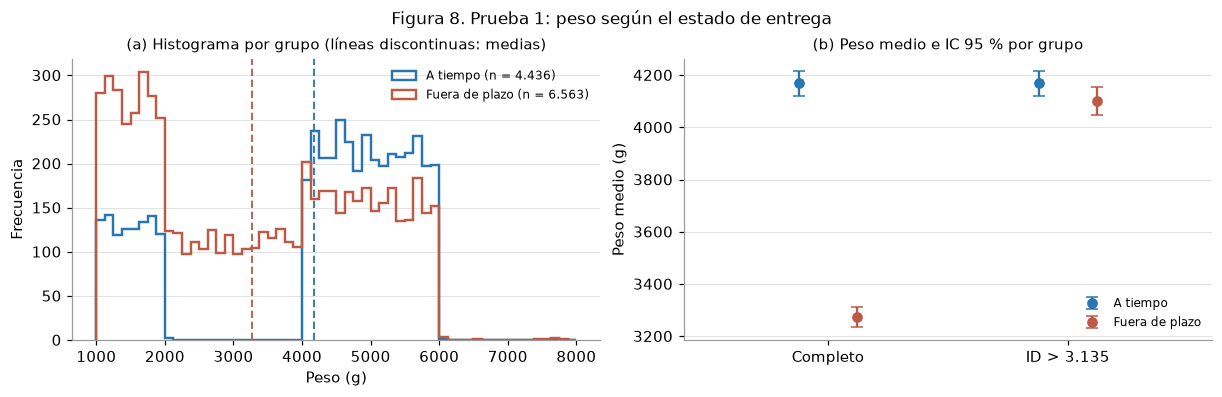

In [19]:
# Figura 8: distribución del peso por estado de entrega.
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
bordes = np.linspace(1000, 8000, 57)
for k in (0, 1):
    serie = df_original.loc[df_original[OBJETIVO] == k, "Weight_in_gms"]
    ejes[0].hist(serie, bins=bordes, histtype="step", lw=1.6,
                 color=COLORES_ESTADO[k], label=f"{ETIQUETAS_ESTADO[k]} (n = {len(serie):,})".replace(",", "."))
    ejes[0].axvline(serie.mean(), color=COLORES_ESTADO[k], ls=(0, (4, 2)), lw=1.2)
ejes[0].set_xlabel("Peso (g)")
ejes[0].set_ylabel("Frecuencia")
ejes[0].set_title("(a) Histograma por grupo (líneas discontinuas: medias)")
ejes[0].legend(fontsize=8)
ejes[0].grid(axis="x", visible=False)

for i, (datos, titulo) in enumerate([(df_original, "Completo"),
                                     (df_sensibilidad, f"ID > {ID_CORTE:,}".replace(",", "."))]):
    for k, desplazamiento in ((0, -0.12), (1, 0.12)):
        serie = datos.loc[datos[OBJETIVO] == k, "Weight_in_gms"]
        r = ic_media_normal(serie)
        ejes[1].errorbar(i + desplazamiento, r["estimacion"],
                         yerr=Z_CRITICO * r["error_estandar"], fmt="o",
                         color=COLORES_ESTADO[k], capsize=4, ms=6,
                         label=ETIQUETAS_ESTADO[k] if i == 0 else None)
ejes[1].set_xticks([0, 1], ["Completo", f"ID > {ID_CORTE:,}".replace(",", ".")])
ejes[1].set_xlim(-0.6, 1.6)
ejes[1].set_ylabel("Peso medio (g)")
ejes[1].set_title("(b) Peso medio e IC 95 % por grupo")
ejes[1].legend(fontsize=8, loc="lower right")
ejes[1].grid(axis="x", visible=False)

fig.suptitle("Figura 8. Prueba 1: peso según el estado de entrega", fontsize=11)
guardar_figura(fig, "fig08_prueba1_peso")
plt.show()

### Interpretación de la prueba 1

**Supuestos.** La independencia de las observaciones se asume y no puede verificarse completamente con la información disponible. La distribución del peso no es normal en ningún grupo (Figura 8a: bimodal en ambos, con asimetría −0,93 en los envíos a tiempo), pero con 6.563 y 4.436 observaciones el tamaño muestral favorece, bajo las condiciones del TCL, que la media muestral sea aproximadamente normal. Las desviaciones estándar son casi idénticas (1.576 y 1.574 g); aun así, la prueba de Levene rechaza la igualdad de dispersión (p < 0,001), porque con la mediana como centro es sensible a la forma de la distribución y no solo a la desviación estándar. Como los tamaños de los grupos también son distintos, se mantiene la prueba de Welch, que evita exigir igualdad de varianzas, pero sigue requiriendo independencia y una aproximación adecuada de la distribución del estadístico.

**Resultado en el dataset completo.** Los envíos fuera de plazo pesan en promedio 896 g menos que los envíos a tiempo (IC 95 % [−956; −836] g). Con t = −29,27, gl ≈ 9.527 y p < 0,001, **se rechaza H₀**. El tamaño del efecto es moderado (d de Cohen = −0,57).

**Sensibilidad.** En el subconjunto ID > 3.135, la diferencia se reduce a 67 g, con d = −0,04 y p = 0,065, por lo que no se rechaza H₀ al 5 %. La Figura 8a explica el cambio: el grupo a tiempo no tiene envíos entre 2.000 y 3.999 g, mientras que el grupo fuera de plazo concentra en ese tramo los registros del bloque inicial. La diferencia de medias proviene casi por completo de ese bloque.

**Implicancia práctica.** El peso no debería utilizarse como criterio para priorizar despachos. La diferencia se atenúa en el subconjunto y no se rechaza la igualdad al 5 %; esto no demuestra ausencia de asociación ni permite considerar al subconjunto más representativo.

### 4.2. Prueba 2: importancia del producto y cumplimiento del plazo

**Pregunta.** ¿El cumplimiento del plazo es independiente de la importancia asignada al producto?

$$H_0: \text{importancia y cumplimiento son independientes} \qquad H_1: \text{están asociados}$$

**Procedimiento.** Ambas variables son categóricas (importancia con tres niveles; cumplimiento binario), por lo que corresponde la prueba χ² de independencia sobre una tabla de contingencia de 3 × 2. Se reporta la V de Cramér como tamaño del efecto, y el riesgo relativo y la razón de odds para el contraste alta frente a baja o media, que tiene una lectura directa para la operación.

**Supuestos.** (1) Observaciones independientes: supuesto no verificable por completo. Cada envío ocupa una sola celda, pero esa condición no prueba independencia. (2) Frecuencias esperadas de al menos 5 en todas las celdas.

In [20]:
def asociacion_chi2(datos, variable, orden=None):
    """Prueba χ² de independencia entre una variable categórica y el retraso."""
    tabla = pd.crosstab(datos[variable], datos[OBJETIVO])
    if orden:
        tabla = tabla.reindex(orden)
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla, correction=False)
    v_cramer = np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))
    return tabla, {"variable": variable, "chi2": chi2, "gl": gl, "p_valor": p,
                   "v_cramer": v_cramer, "esperada_minima": esperadas.min()}


tabla_p2, p2 = asociacion_chi2(df_original, "Product_importance", ORDEN_IMPORTANCIA)
tabla_p2_completa = tabla_p2.rename(columns=ETIQUETAS_ESTADO)
tabla_p2_completa["total"] = tabla_p2_completa.sum(axis=1)
tabla_p2_completa["pct_fuera_plazo"] = tabla_p2[1] / tabla_p2.sum(axis=1) * 100
guardar_tabla(tabla_p2_completa, "tab13_prueba2_contingencia")

# Tamaño del efecto práctico: importancia alta frente al resto (tabla 2×2).
a = tabla_p2.loc["high", 1]; b = tabla_p2.loc["high", 0]
c = tabla_p2.drop("high")[1].sum(); d = tabla_p2.drop("high")[0].sum()
riesgo_alta, riesgo_resto = a / (a + b), c / (c + d)
rr = riesgo_alta / riesgo_resto
odds_ratio = (a * d) / (b * c)
ee_log_or = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
or_ic = np.exp(np.log(odds_ratio) + np.array([-1, 1]) * Z_CRITICO * ee_log_or)
p2.update({"pct_alta": riesgo_alta * 100, "pct_resto": riesgo_resto * 100,
           "riesgo_relativo": rr, "odds_ratio": odds_ratio,
           "or_ic_inferior": or_ic[0], "or_ic_superior": or_ic[1]})
guardar_tabla(pd.Series(p2).to_frame("valor"), "tab14_prueba2_chi2_importancia")

print("Tablas 13 y 14. Prueba 2: importancia del producto y cumplimiento del plazo (χ² de independencia)\n")
print("Tabla de contingencia")
display(tabla_p2_completa.round(2))
print(f"Frecuencia esperada mínima: {p2['esperada_minima']:.0f} (supuesto: ≥ 5 en todas las celdas)")
print(f"χ² = {p2['chi2']:.2f}   gl = {p2['gl']}   p = {p2['p_valor']:.4f}   V de Cramér = {p2['v_cramer']:.3f}")
print(f"Fuera de plazo: alta = {riesgo_alta:.1%}, baja o media = {riesgo_resto:.1%}")
print(f"Riesgo relativo = {rr:.3f}   Odds ratio = {odds_ratio:.3f}  "
      f"IC 95 % [{or_ic[0]:.3f}; {or_ic[1]:.3f}]")
print("Decisión:", "se rechaza H0" if p2["p_valor"] < ALFA else "no se rechaza H0")

# Sensibilidad: misma prueba en el subconjunto ID > ID_CORTE.
tabla_p2_sens, p2_sens = asociacion_chi2(df_sensibilidad, "Product_importance", ORDEN_IMPORTANCIA)
pct_sens = tabla_p2_sens[1] / tabla_p2_sens.sum(axis=1) * 100
guardar_tabla(pd.Series(p2_sens).to_frame("valor"), "tab14b_prueba2_chi2_sensibilidad")
print(f"\nSensibilidad (ID > {ID_CORTE}): % fuera de plazo por importancia "
      + ", ".join(f"{nivel} = {valor:.2f}" for nivel, valor in pct_sens.items()))
print(f"  χ² = {p2_sens['chi2']:.2f}   gl = {p2_sens['gl']}   p = {p2_sens['p_valor']:.4f}   "
      f"V de Cramér = {p2_sens['v_cramer']:.3f}")

Tablas 13 y 14. Prueba 2: importancia del producto y cumplimiento del plazo (χ² de independencia)

Tabla de contingencia


Reached.on.Time_Y.N,A tiempo,Fuera de plazo,total,pct_fuera_plazo
Product_importance,,,,
low,2157,3140,5297,59.28
medium,1947,2807,4754,59.05
high,332,616,948,64.98


Frecuencia esperada mínima: 382 (supuesto: ≥ 5 en todas las celdas)
χ² = 12.21   gl = 2   p = 0.0022   V de Cramér = 0.033
Fuera de plazo: alta = 65.0%, baja o media = 59.2%
Riesgo relativo = 1.098   Odds ratio = 1.280  IC 95 % [1.114; 1.472]
Decisión: se rechaza H0

Sensibilidad (ID > 3135): % fuera de plazo por importancia low = 43.86, medium = 42.55, high = 47.55
  χ² = 5.64   gl = 2   p = 0.0595   V de Cramér = 0.027


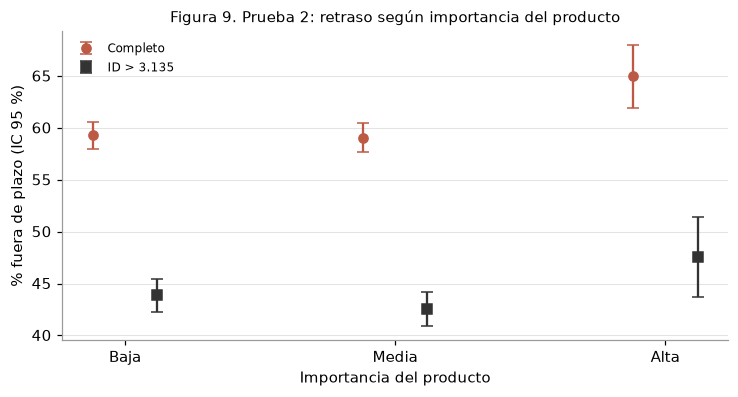

In [21]:
# Figura 9: porcentaje fuera de plazo por importancia, con IC de Wilson al 95 %.
fig, ax = plt.subplots(figsize=(6.6, 3.5), layout="constrained")
for i, (datos, titulo, desplazamiento, marcador) in enumerate([
        (df_original, "Completo", -0.12, "o"),
        (df_sensibilidad, f"ID > {ID_CORTE:,}".replace(",", "."), 0.12, "s")]):
    tabla = pd.crosstab(datos["Product_importance"], datos[OBJETIVO]).reindex(ORDEN_IMPORTANCIA)
    for j, nivel in enumerate(ORDEN_IMPORTANCIA):
        k, n = tabla.loc[nivel, 1], tabla.loc[nivel].sum()
        r = ic_proporcion_wilson(k, n)
        ax.errorbar(j + desplazamiento, r["estimacion"] * 100,
                    yerr=[[(r["estimacion"] - r["ic_inferior"]) * 100],
                          [(r["ic_superior"] - r["estimacion"]) * 100]],
                    fmt=marcador, color=COLOR_FUERA_PLAZO if i == 0 else "#333333",
                    capsize=4, ms=6, label=titulo if j == 0 else None)
ax.set_xticks(range(3), ["Baja", "Media", "Alta"])
ax.set_xlabel("Importancia del producto")
ax.set_ylabel("% fuera de plazo (IC 95 %)")
ax.legend(fontsize=8, loc="upper left")
ax.grid(axis="x", visible=False)
ax.set_title("Figura 9. Prueba 2: retraso según importancia del producto")
guardar_figura(fig, "fig09_prueba2_importancia")
plt.show()

### Interpretación de la prueba 2

Las frecuencias esperadas satisfacen el criterio de aproximación (mínima 382 en el conjunto completo); la independencia se mantiene como supuesto. En el dataset completo, χ² = 12,21, gl = 2 y p = 0,00223 permiten rechazar H₀ al 5 %. La intensidad global es pequeña (V de Cramér = 0,033). La importancia alta presenta un 65,0 % de retraso frente a 59,2 % en el resto; RR = 1,10 y OR = 1,28, con IC 95 % de OR [1,11; 1,47].

En ID > 3135, el contraste global entre las tres categorías da p = 0,05950 y no se rechaza H₀ al 5 %. Esto no demuestra igualdad de tasas. El contraste específico alta frente al resto se informa en la sección siguiente y responde una pregunta diferente. El valor p del conjunto completo no está próximo a 0,05.

La mayor tasa observada en importancia alta no permite deducir qué política de prioridad aplica la empresa ni que la clasificación cause retrasos. Su relevancia operativa requiere contexto y validación adicional.


### 4.3. Pruebas complementarias

Se incluyen dos contrastes adicionales. La **prueba z de dos proporciones** compara directamente el porcentaje fuera de plazo de la importancia alta con el de la importancia baja o media. Es equivalente a una prueba χ² de 2 × 2 sin corrección (z² = χ²) y corresponde al procedimiento del ejemplo de la Formativa 1. La **prueba χ² del medio de transporte** evalúa una variable que, por su relevancia operacional, podría parecer candidata natural para explicar los retrasos.

- Prueba z: $H_0: p_{\text{alta}} = p_{\text{baja o media}}$ frente a $H_1: p_{\text{alta}} \neq p_{\text{baja o media}}$, con α = 0,05.
- Prueba χ²: $H_0$: medio de transporte y cumplimiento son independientes, frente a $H_1$: están asociados, con α = 0,05.

In [22]:
def comparar_proporciones_importancia(datos):
    """Contraste bilateral exploratorio: importancia alta frente al resto."""
    alta = datos.loc[datos["Product_importance"].eq("high"), OBJETIVO]
    resto = datos.loc[~datos["Product_importance"].eq("high"), OBJETIVO]
    n1, n0 = len(alta), len(resto)
    k1, k0 = int(alta.sum()), int(resto.sum())
    p1, p0 = k1 / n1, k0 / n0
    #Cálculo de "z"
    combinada = (k1 + k0) / (n1 + n0)
    minimo_esperado = min(n1 * combinada, n1 * (1-combinada),
                          n0 * combinada, n0 * (1-combinada))
    ee = np.sqrt(combinada * (1-combinada) * (1/n1 + 1/n0))
    z = (p1-p0)/ee
    ee_ic = np.sqrt(p1*(1-p1)/n1 + p0*(1-p0)/n0)
    return {"n_alta": n1, "n_resto": n0, "retrasos_alta": k1,
            "retrasos_resto": k0, "tasa_alta": p1, "tasa_resto": p0,
            "diferencia_pp": 100*(p1-p0), "estadistico": z,
            "p_valor": 2*stats.norm.sf(abs(z)),
            "esperada_minima": minimo_esperado,
            "aproximacion_conteos_ok": minimo_esperado >= 10,
            "ic_diferencia_inferior_pp": 100*(p1-p0-Z_CRITICO*ee_ic),
            "ic_diferencia_superior_pp": 100*(p1-p0+Z_CRITICO*ee_ic)}

z_completo = comparar_proporciones_importancia(df_original)
z_sensibilidad = comparar_proporciones_importancia(df_sensibilidad)
tabla_modo, p_modo = asociacion_chi2(df_original, "Mode_of_Shipment")
complementos = pd.DataFrame([
    {"prueba": "z alta frente al resto", "conjunto": "Completo", **z_completo},
    {"prueba": "z alta frente al resto", "conjunto": f"ID > {ID_CORTE}", **z_sensibilidad},
    {"prueba": "χ² medio de transporte", "conjunto": "Completo",
     "estadistico": p_modo["chi2"], "gl": p_modo["gl"],
     "p_valor": p_modo["p_valor"], "v_cramer": p_modo["v_cramer"]},
])
guardar_tabla(complementos, "tab15_pruebas_complementarias", index=False)
print("Tabla 15. Contrastes complementarios; valores p sin ajuste por multiplicidad")
display(complementos.round(6))
assert z_completo["aproximacion_conteos_ok"] and z_sensibilidad["aproximacion_conteos_ok"]


Tabla 15. Contrastes complementarios; valores p sin ajuste por multiplicidad


,prueba,conjunto,n_alta,n_resto,retrasos_alta,retrasos_resto,tasa_alta,tasa_resto,diferencia_pp,estadistico,p_valor,esperada_minima,aproximacion_conteos_ok,ic_diferencia_inferior_pp,ic_diferencia_superior_pp,gl,v_cramer
0,z alta frente al resto,Completo,948.0,10051.0,616.0,5947.0,0.649789,0.591682,5.810661,3.486294,0.000490,382.337303,True,2.625599,8.995723,NaN,NaN
1,z alta frente al resto,ID > 3135,633.0,7231.0,301.0,3127.0,0.475513,0.432444,4.306978,2.095460,0.036130,275.931333,True,0.252459,8.361498,NaN,NaN
2,χ² medio de transporte,Completo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.743436,0.689549,NaN,NaN,NaN,NaN,2.0,0.008221


### Interpretación de las pruebas complementarias

En el conjunto completo, la diferencia alta menos resto es 5,81 puntos porcentuales (z = 3,486; p = 0,000490). En ID > 3135, las tasas son 47,55 % y 43,24 %, diferencia de 4,31 puntos porcentuales (z = 2,095; p = 0,03613). El contraste conserva dirección y significancia nominal al 5 % en esta comparación.

La prueba χ² de tres categorías evalúa la igualdad global de sus tasas, mientras que la z compara alta con baja y media agrupadas. Por ello sus decisiones pueden diferir. La equivalencia z² = χ² corresponde a la tabla 2 × 2 sin corrección, no al contraste de tres categorías. El contraste alta/resto se eligió tras observar la descriptiva y el subconjunto se definió post hoc: ambos análisis son exploratorios y no constituyen validación independiente. La tabla informa conteos esperados y un IC aproximado para la diferencia; la independencia permanece como supuesto.

Para el medio de transporte no se detectó evidencia de asociación (p = 0,690; V = 0,008). Esto no demuestra ausencia de asociación ni permite estimar el efecto causal de cambiar el transporte.


### 4.4. Análisis de sensibilidad consolidado

Se comparan los contrastes en el conjunto completo y en ID > 3135. La tabla distingue cambios de significancia nominal y, cuando corresponde, de dirección. “No significativo en ambos” no significa efecto inexistente. Mantener significancia y dirección en esta comparación no demuestra robustez general.

El corte y los contrastes complementarios son exploratorios; el subconjunto está contenido en la muestra original y no es una validación independiente. Se reportan valores p sin ajuste por multiplicidad y tamaños de efecto, sin establecer cuál conjunto representa mejor a la población.


In [23]:
def clasificar(p_completo, p_reducido, efecto_completo, efecto_reducido,
               con_signo, alfa=ALFA):
    """Etiqueta de robustez: exige la misma decisión y, si el efecto tiene
    signo (d de Cohen), la misma dirección en ambos conjuntos."""
    sig_c, sig_r = p_completo < alfa, p_reducido < alfa
    if not sig_c and not sig_r:
        return "No significativo en ambos"
    if sig_c != sig_r:
        return "Sensible: cambia la decisión"
    if con_signo and np.sign(efecto_completo) != np.sign(efecto_reducido):
        return "Sensible: invierte el signo"
    return "Mantiene significancia y dirección" if con_signo else "Mantiene significancia global"


filas = []
for variable, etiqueta in [("Discount_offered", "Descuento (t de Welch)"),
                           ("Weight_in_gms", "Peso (t de Welch)"),
                           ("Cost_of_the_Product", "Costo (t de Welch)"),
                           ("Customer_care_calls", "Llamadas (t de Welch)")]:
    r_c = comparar_medias_welch(df_original, variable)
    r_s = comparar_medias_welch(df_sensibilidad, variable)
    filas.append({"contraste": etiqueta,
                  "efecto": "d de Cohen",
                  "efecto_completo": r_c["d_cohen"], "p_completo": r_c["p_valor"],
                  "efecto_sensibilidad": r_s["d_cohen"], "p_sensibilidad": r_s["p_valor"]})

for variable, etiqueta, orden in [("Product_importance", "Importancia (χ²)", ORDEN_IMPORTANCIA),
                                  ("Mode_of_Shipment", "Medio de transporte (χ²)", None),
                                  ("Warehouse_block", "Bloque de almacén (χ²)", None)]:
    _, r_c = asociacion_chi2(df_original, variable, orden)
    _, r_s = asociacion_chi2(df_sensibilidad, variable, orden)
    filas.append({"contraste": etiqueta,
                  "efecto": "V de Cramér",
                  "efecto_completo": r_c["v_cramer"], "p_completo": r_c["p_valor"],
                  "efecto_sensibilidad": r_s["v_cramer"], "p_sensibilidad": r_s["p_valor"]})

filas.append({"contraste": "Importancia alta vs. resto (z)",
              "efecto": "Diferencia en puntos porcentuales",
              "efecto_completo": z_completo["diferencia_pp"],
              "p_completo": z_completo["p_valor"],
              "efecto_sensibilidad": z_sensibilidad["diferencia_pp"],
              "p_sensibilidad": z_sensibilidad["p_valor"]})
tabla_sensibilidad = pd.DataFrame(filas)
tabla_sensibilidad["clasificacion"] = [
    clasificar(f.p_completo, f.p_sensibilidad, f.efecto_completo,
               f.efecto_sensibilidad, f.efecto in ("d de Cohen", "Diferencia en puntos porcentuales"))
    for f in tabla_sensibilidad.itertuples()]
guardar_tabla(tabla_sensibilidad, "tab16_sensibilidad_pruebas", index=False)
print(f"Tabla 16. Pruebas en el dataset completo (n = {len(df_original):,}) "
      f"y en ID > {ID_CORTE} (n = {len(df_sensibilidad):,})")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(tabla_sensibilidad)

Tabla 16. Pruebas en el dataset completo (n = 10,999) y en ID > 3135 (n = 7,864)


,contraste,efecto,efecto_completo,p_completo,efecto_sensibilidad,p_sensibilidad,clasificacion
0,Descuento (t de Welch),d de Cohen,0.8819,0,-0.02071,0.3628,Sensible: cambia la decisión
1,Peso (t de Welch),d de Cohen,-0.5688,1.931e-180,-0.04211,0.06451,Sensible: cambia la decisión
2,Costo (t de Welch),d de Cohen,-0.1504,1.036e-14,0.06511,0.004223,Sensible: invierte el signo
3,Llamadas (t de Welch),d de Cohen,-0.1371,2.597e-12,0.0569,0.01259,Sensible: invierte el signo
4,Importancia (χ²),V de Cramér,0.03332,0.00223,0.02679,0.0595,Sensible: cambia la decisión
5,Medio de transporte (χ²),V de Cramér,0.008221,0.6895,0.01047,0.6499,No significativo en ambos
6,Bloque de almacén (χ²),V de Cramér,0.009952,0.896,0.014,0.8191,No significativo en ambos
7,Importancia alta vs. resto (z),Diferencia en puntos porcentuales,5.811,0.0004898,4.307,0.03613,Mantiene significancia y dirección


Tabla 17. % fuera de plazo por número de llamadas: completo frente a ID > 3135


,completo,sensibilidad,n_completo,pct_en_bloque_inicial
Customer_care_calls,,,,
2,65.20,41.42,638,40.60
3,62.51,42.43,3217,34.88
4,59.77,43.15,3557,29.24
5,58.42,44.46,2328,25.13
6,51.63,44.94,1013,12.14
7,51.63,50.42,246,2.44


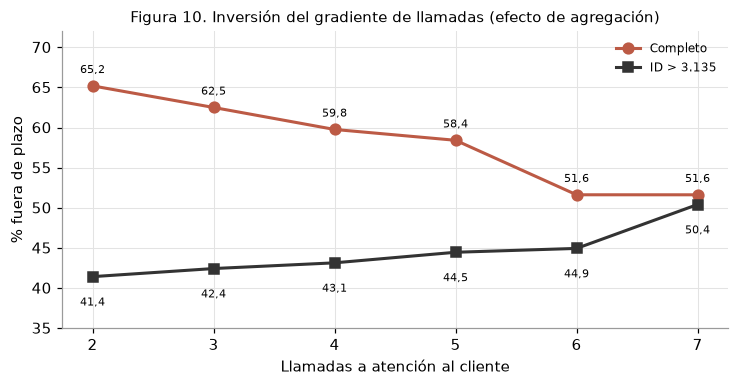

In [24]:
# Paradoja de Simpson en las llamadas: porcentaje fuera de plazo por número de llamadas.
llamadas = pd.DataFrame({
    "completo": df_original.groupby("Customer_care_calls")[OBJETIVO].mean() * 100,
    "sensibilidad": df_sensibilidad.groupby("Customer_care_calls")[OBJETIVO].mean() * 100,
    "n_completo": df_original["Customer_care_calls"].value_counts().sort_index(),
    "pct_en_bloque_inicial": df_original.groupby("Customer_care_calls")["ID"]
                             .apply(lambda s: (s <= ID_CORTE).mean() * 100),
})
guardar_tabla(llamadas, "tab17_llamadas_simpson")
print(f"Tabla 17. % fuera de plazo por número de llamadas: completo frente a ID > {ID_CORTE}")
display(llamadas.round(2))

fig, ax = plt.subplots(figsize=(6.6, 3.4), layout="constrained")
ax.plot(llamadas.index, llamadas["completo"], marker="o", color=COLOR_FUERA_PLAZO,
        lw=2, ms=7, label="Completo")
ax.plot(llamadas.index, llamadas["sensibilidad"], marker="s", color="#333333",
        lw=2, ms=7, label=f"ID > {ID_CORTE:,}".replace(",", "."))
for serie, desplazamiento in (("completo", 1.6), ("sensibilidad", -3.6)):
    for x, y in llamadas[serie].items():
        ax.text(x, y + desplazamiento, formato_es(y), ha="center", fontsize=7.5)
ax.set_xlabel("Llamadas a atención al cliente")
ax.set_ylabel("% fuera de plazo")
ax.set_ylim(35, 72)
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Figura 10. Inversión del gradiente de llamadas (efecto de agregación)")
guardar_figura(fig, "fig10_simpson_llamadas")
plt.show()

### Interpretación del análisis de sensibilidad

- **Descuento:** el efecto se reduce de d = 0,88 a aproximadamente −0,02 (p = 0,363). La restricción del rango a 1–10 y el cambio de composición impiden atribuir el cambio a una sola causa. No se demuestra igualdad de medias.
- **Peso:** la diferencia se atenúa a −66,62 g, IC 95 % [−137,26; 4,01], p = 0,06451. No rechazar H₀ no demuestra ausencia de efecto.
- **Costo y llamadas:** conservan significancia nominal pero invierten la dirección; los efectos en el subconjunto son pequeños (|d| < 0,07). El patrón es compatible con un efecto de agregación asociado a la composición por bloques.
- **Importancia:** el contraste global de tres categorías no resulta significativo en el subconjunto (p = 0,05950); alta frente al resto sí conserva una diferencia positiva y significancia nominal (4,31 puntos; p = 0,03613).
- **Transporte y almacén:** no se detectó evidencia de asociación en ninguno de los dos conjuntos.

La persistencia del contraste alta/resto es una señal exploratoria, no una asociación validada. El corte post hoc, la multiplicidad de contrastes y el origen poco documentado limitan las conclusiones. Las correlaciones numéricas pequeñas tampoco descartan relaciones no lineales o multivariadas.


## 5. Síntesis de resultados y próximos pasos

**Calidad y origen.** Se analizaron 10.999 registros, sin faltantes ni duplicados y sin incumplimientos de los controles básicos de dominio. Esto no demuestra ausencia de errores. No se documentan la empresa, el período de observación ni el mecanismo de muestreo. El bloque inicial de 3.135 envíos, todos fuera de plazo, condiciona varias asociaciones; su origen no puede deducirse a partir de estos patrones.

**Estimación.** La proporción observada fuera de plazo es 59,67 %, con intervalo de Wald [58,75 %; 60,59 %]. El 95 % es la cobertura nominal del procedimiento bajo sus supuestos. Se estiman también las medias de costo, peso y descuento. Los intervalos estrechos no resuelven sesgos de selección ni incertidumbre sobre la composición del archivo.

**Pruebas.** Welch para peso y χ² para importancia rechazan sus hipótesis nulas en el conjunto completo. En la sensibilidad, peso no alcanza significancia al 5 % y el contraste global de importancia tampoco. El contraste exploratorio alta/resto conserva dirección y significancia nominal (p = 0,03613), con diferencia de 4,31 puntos porcentuales. Costo y llamadas invierten el signo; transporte y almacén no muestran evidencia suficiente de asociación.

**Decisión.** Ninguna variable justifica por sí sola una intervención logística con la evidencia disponible. La señal de importancia alta merece validación adicional, sin inferir causas ni políticas de prioridad. Antes de usar descuento, llamadas o calificación como predictores, debe establecerse su momento de registro para evitar fuga de información.

**Próximos pasos.** Se proponen remuestreo y análisis de estabilidad, sujetos a la rúbrica de la fase correspondiente. Remuestrear el mismo archivo no corrige su representatividad ni constituye validación externa. La tabla siguiente recoge propuestas, no requisitos adicionales de S1.


In [25]:
# Insumos que esta fase entrega a las sumativas 2 y 3.
insumos = pd.DataFrame([
    ("S2 · Bootstrap de IC",
     "Medias de costo, peso y descuento; proporción fuera de plazo (Tabla 10)",
     "Comparar IC percentil y BCa con los IC normales; el descuento (asimetría alta) "
     "y el peso (bimodal) son los casos donde se esperan discrepancias."),
    ("S2 · Permutación",
     "Prueba 1 (Welch, peso) y Prueba 2 (χ², importancia)",
     "Contrastar los valores p con ≥ 10.000 permutaciones, en el completo y en ID > corte."),
    ("S2 · Estabilidad de correlaciones",
     "ρ de Spearman de descuento y peso con el retraso (Tabla 5)",
     "IC bootstrap de ρ; evaluar si la asociación depende del bloque inicial."),
    ("S2 · Monte Carlo",
     "p̂ fuera de plazo, medias y desviaciones por grupo (Tablas 7 y 10)",
     "Simular escenarios de retraso con los parámetros estimados y su incertidumbre."),
    ("S2 · Robustez",
     "Bloque ID ≤ corte y reglas de frontera (Tablas 8, 9 y 16)",
     "Tratar el bloque como subpoblación influyente; reportar qué resultados sobreviven."),
    ("S3 · Imputación",
     "0 faltantes (sección 1.1)",
     "La imputación por regresión requerirá inducir faltantes de forma controlada (MCAR/MAR) "
     "y comparar estrategias contra el valor real conocido."),
    ("S3 · Regresión logística",
     "Descuento > 10 ⇒ 100 % fuera de plazo (Tabla 9)",
     "Anticipar separación casi perfecta: coeficientes y odds ratios inestables "
     "si se incluye el descuento sin tratamiento."),
], columns=["destino", "insumo_s1", "uso_previsto"])
guardar_tabla(insumos, "tab18_insumos_s2_s3", index=False)
print("Tabla 18. Insumos de la Sumativa 1 para las fases siguientes")
with pd.option_context("display.max_colwidth", None):
    display(insumos)

Tabla 18. Insumos de la Sumativa 1 para las fases siguientes


,destino,insumo_s1,uso_previsto
0,S2 · Bootstrap de IC,"Medias de costo, peso y descuento; proporción fuera de plazo (Tabla 10)",Comparar IC percentil y BCa con los IC normales; el descuento (asimetría alta) y el peso (bimodal) son los casos donde se esperan discrepancias.
1,S2 · Permutación,"Prueba 1 (Welch, peso) y Prueba 2 (χ², importancia)","Contrastar los valores p con ≥ 10.000 permutaciones, en el completo y en ID > corte."
2,S2 · Estabilidad de correlaciones,ρ de Spearman de descuento y peso con el retraso (Tabla 5),IC bootstrap de ρ; evaluar si la asociación depende del bloque inicial.
3,S2 · Monte Carlo,"p̂ fuera de plazo, medias y desviaciones por grupo (Tablas 7 y 10)",Simular escenarios de retraso con los parámetros estimados y su incertidumbre.
4,S2 · Robustez,"Bloque ID ≤ corte y reglas de frontera (Tablas 8, 9 y 16)",Tratar el bloque como subpoblación influyente; reportar qué resultados sobreviven.
5,S3 · Imputación,0 faltantes (sección 1.1),La imputación por regresión requerirá inducir faltantes de forma controlada (MCAR/MAR) y comparar estrategias contra el valor real conocido.
6,S3 · Regresión logística,Descuento > 10 ⇒ 100 % fuera de plazo (Tabla 9),Anticipar separación casi perfecta: coeficientes y odds ratios inestables si se incluye el descuento sin tratamiento.


## 6. Reproducibilidad

- **Entorno:** la tabla de la sección 0 registra las versiones de Python y de las librerías usadas; las versiones efectivamente utilizadas deben contrastarse con `requirements.txt` al reproducir el análisis.
- **Datos:** el archivo original se lee desde `datos/originales/ecommerce-shipping.csv` y no se modifica. No se versiona en el repositorio; el README indica cómo obtenerlo.
- **Ejecución:** el notebook se ejecuta de principio a fin en orden lineal. Ninguna celda depende de una ejecución fuera de orden.
- **Semilla:** `SEED = 42`. S1 no usa procedimientos aleatorios; la semilla queda definida para las sumativas 2 y 3.
- **Salidas:** cada tabla (`tabNN_*.csv`) y figura (`figNN_*.png`) citada en los informes se regenera al ejecutar el notebook.

## Referencias

- Wasserstein, R. L. y Lazar, N. A. (2016). The ASA statement on p-values: Context, process, and purpose. *The American Statistician, 70*(2), 129–133. https://doi.org/10.1080/00031305.2016.1154108
- Flórez Oviedo, N. E. y López Hincapié, E. (2023). Evolución de la logística de la última milla. Revisión de la literatura. *Ingeniería Industrial, 44*(2), 1–14.
- Prachi13. (s. f.). *E-Commerce Shipping Data* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/prachi13/customer-analytics
- Stevens, S. S. (1946). On the theory of scales of measurement. *Science, 103*(2684), 677–680. https://doi.org/10.1126/science.103.2684.677
- Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Welch, B. L. (1947). The generalization of "Student's" problem when several different population variances are involved. *Biometrika, 34*(1–2), 28–35. https://doi.org/10.1093/biomet/34.1-2.28
- National Institute of Standards and Technology (NIST). (s. f.-a). *Measures of Location*. https://www.itl.nist.gov/div898/handbook/eda/section3/eda351.htm
- National Institute of Standards and Technology (NIST). (s. f.-b). *Measures of Scale*. https://www.itl.nist.gov/div898/handbook/eda/section3/eda356.htm
